### Step 1: Load and inspect the Phase 4 dataset

In [1]:
# Load the Phase 4 dataset and inspect its structure
import duckdb
import pandas as pd

con = duckdb.connect()

dataset_path = "../data/processed/features_day_d.parquet"

dataset_info = con.execute(f"""
    DESCRIBE SELECT *
    FROM read_parquet('{dataset_path}')
""").df()

display(dataset_info)

,column_name,column_type,null,key,default,extra
0,LCLid,VARCHAR,YES,None,None,None
1,month,DATE,YES,None,None,None
2,d,INTEGER,YES,None,None,None
3,kwh_to_date,DOUBLE,YES,None,None,None
4,days_elapsed,INTEGER,YES,None,None,None
5,days_remaining,BIGINT,YES,None,None,None
6,daily_mean_to_date,DOUBLE,YES,None,None,None
7,last7_mean_kwh,DOUBLE,YES,None,None,None
8,run_rate_kwh,DOUBLE,YES,None,None,None
9,previous_month_kwh,DOUBLE,YES,None,None,None


### Step 2: Dataset Overview

This step examines the size and coverage of the modeling dataset. It identifies the number of households, billing months, available forecasting days, and the date range. These details will help determine an appropriate chronological split for model training, validation, and testing.

In [2]:
# Check dataset size, forecasting days, and date coverage
dataset_summary = con.execute(f"""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT LCLid) AS households,
        COUNT(DISTINCT month) AS billing_months,
        MIN(month) AS first_month,
        MAX(month) AS last_month,
        COUNT(DISTINCT d) AS forecast_days,
        COUNT(*) FILTER (WHERE d = 7) AS day_7_rows,
        COUNT(*) FILTER (WHERE d = 14) AS day_14_rows,
        COUNT(*) FILTER (WHERE d = 21) AS day_21_rows
    FROM read_parquet('{dataset_path}')
""").df()

display(dataset_summary)

,total_rows,households,billing_months,first_month,last_month,forecast_days,day_7_rows,day_14_rows,day_21_rows
0,254421,4428,26,2011-12-01,2014-01-01,3,84807,84807,84807


### Step 3: Monthly Data Distribution

This step examines the number of household-month observations available in each billing month. The distribution will help assess data coverage and guide the selection of chronological training, validation, and testing periods.

In [3]:
# Count household-month observations across the dataset
monthly_distribution = con.execute(f"""
    SELECT
        month,
        COUNT(DISTINCT LCLid) AS households,
        COUNT(*) AS total_observations
    FROM read_parquet('{dataset_path}')
    WHERE d = 7
    GROUP BY month
    ORDER BY month
""").df()

display(monthly_distribution)

,month,households,total_observations
0,2011-12-01,61,61
1,2012-01-01,351,351
2,2012-02-01,491,491
3,2012-03-01,706,706
4,2012-04-01,1018,1018
5,2012-05-01,1699,1699
6,2012-06-01,2888,2888
7,2012-07-01,3343,3343
8,2012-08-01,3751,3751
9,2012-09-01,3766,3766


### Step 4: Missing Value Assessment

This step examines missing values across all columns in the modeling dataset. The number and percentage of missing values are calculated to identify incomplete features and guide appropriate preprocessing before model training.

In [4]:
# Calculate missing-value counts and percentages for each column
missing_values = con.execute(f"""
    SELECT *
    FROM read_parquet('{dataset_path}')
""").df()

missing_summary = pd.DataFrame({
    "missing_count": missing_values.isna().sum(),
    "missing_percentage": (
        missing_values.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="missing_percentage",
    ascending=False
)

display(missing_summary)

,missing_count,missing_percentage
same_month_ly_bill_gbp,156657,61.57
same_month_last_year_kwh,156657,61.57
rolling_3month_kwh,41415,16.28
last_month_bill_gbp,14004,5.50
previous_month_kwh,14004,5.50
holidays_remaining,0,0.00
runrate_bill_gbp,0,0.00
final_bill_gbp,0,0.00
month_kwh,0,0.00
remaining_kwh,0,0.00


#### Missing Value Assessment: Findings

Missing values occur only in historical consumption features and their corresponding benchmark columns. The highest missingness is observed in same-month-last-year consumption (61.57%), followed by rolling three-month consumption (16.28%) and previous-month consumption (5.50%). All other features, including the prediction target, are complete. Historical features will be retained for initial modeling, with missing values handled using appropriate training-based preprocessing.

### Step 5: Historical Feature Availability Over Time

This step examines the percentage of available historical consumption values for each billing month. The analysis helps determine whether missingness is associated with insufficient household history and informs subsequent preprocessing decisions.

In [5]:
# Calculate monthly availability of historical consumption features
history_availability = con.execute(f"""
    SELECT
        month,
        COUNT(*) AS households,
        ROUND(100.0 * COUNT(previous_month_kwh) / COUNT(*), 2)
            AS previous_month_pct,
        ROUND(100.0 * COUNT(rolling_3month_kwh) / COUNT(*), 2)
            AS rolling_3month_pct,
        ROUND(100.0 * COUNT(same_month_last_year_kwh) / COUNT(*), 2)
            AS same_month_last_year_pct
    FROM read_parquet('{dataset_path}')
    WHERE d = 7
    GROUP BY month
    ORDER BY month
""").df()

display(history_availability)

,month,households,previous_month_pct,rolling_3month_pct,same_month_last_year_pct
0,2011-12-01,61,0.00,0.00,0.00
1,2012-01-01,351,17.38,0.00,0.00
2,2012-02-01,491,71.28,0.00,0.00
3,2012-03-01,706,69.26,8.64,0.00
4,2012-04-01,1018,69.16,34.38,0.00
5,2012-05-01,1699,59.80,28.72,0.00
6,2012-06-01,2888,58.21,24.31,0.00
7,2012-07-01,3343,86.12,30.27,0.00
8,2012-08-01,3751,88.67,44.33,0.00
9,2012-09-01,3766,99.36,75.84,0.00


#### Historical Feature Availability: Findings

Historical feature availability generally increases over time as household consumption records accumulate. Previous-month and rolling three-month consumption become nearly complete during 2013, while same-month-last-year consumption reaches approximately 99% toward the end of 2013. This suggests that missingness is largely associated with limited historical records. The features will be retained, with missing values handled during model preprocessing.

### Step 6: Expanding-Window Validation

Three expanding-window validation folds are used to evaluate model performance across successive periods while maintaining chronological order. The training window expands after each fold, and October 2013–January 2014 is reserved for final testing. All forecasting observations from the same household-month remain in the same partition to prevent leakage.

| Fold | Training period | Validation period |
|---|---|---|
| 1 | Dec 2011 – Dec 2012 | Jan – Mar 2013 |
| 2 | Dec 2011 – Mar 2013 | Apr – Jun 2013 |
| 3 | Dec 2011 – Jun 2013 | Jul – Sep 2013 |
| Final test | Dec 2011 – Sep 2013 | Oct 2013 – Jan 2014 |

In [6]:
# Define expanding-window validation folds and final test boundaries
validation_folds = [
    ("2012-12-01", "2013-01-01", "2013-03-01"),
    ("2013-03-01", "2013-04-01", "2013-06-01"),
    ("2013-06-01", "2013-07-01", "2013-09-01"),
]

test_start = "2013-10-01"

split_summary = []

for fold, (train_end, val_start, val_end) in enumerate(validation_folds, 1):
    counts = con.execute(f"""
        SELECT
            COUNT(*) FILTER (
                WHERE month <= DATE '{train_end}'
            ) AS train_rows,
            COUNT(*) FILTER (
                WHERE month BETWEEN DATE '{val_start}' AND DATE '{val_end}'
            ) AS validation_rows
        FROM read_parquet('{dataset_path}')
    """).df().iloc[0]

    split_summary.append({
        "fold": fold,
        "train_end": train_end,
        "validation_start": val_start,
        "validation_end": val_end,
        "train_rows": int(counts["train_rows"]),
        "validation_rows": int(counts["validation_rows"])
    })

display(pd.DataFrame(split_summary))

# Count observations for final model training and testing
test_summary = con.execute(f"""
    SELECT
        COUNT(*) FILTER (
            WHERE month < DATE '{test_start}'
        ) AS final_train_rows,
        COUNT(*) FILTER (
            WHERE month >= DATE '{test_start}'
        ) AS test_rows
    FROM read_parquet('{dataset_path}')
""").df()

display(test_summary)

,fold,train_end,validation_start,validation_end,train_rows,validation_rows
0,1,2012-12-01,2013-01-01,2013-03-01,92247,38676
1,2,2013-03-01,2013-04-01,2013-06-01,130923,37983
2,3,2013-06-01,2013-07-01,2013-09-01,168906,37194


,final_train_rows,test_rows
0,206100,48321


#### Expanding-Window Validation: Findings

The three validation folds contain progressively larger training sets, ranging from 92,247 to 168,906 observations. Validation sets contain approximately 37,000–39,000 observations each. For final evaluation, 206,100 observations are available for training and 48,321 are reserved for testing. The chronological separation ensures that each model is trained on earlier months and evaluated on subsequent months.

### Step 7: Predictor and Target Selection

This step identifies the input features used to predict remaining monthly electricity consumption. Household identifiers, future-dependent outcomes, and benchmark columns are excluded to prevent information leakage. The prediction target is `remaining_kwh`, representing electricity consumption from the forecasting day to the end of the billing month.

In [7]:
# Define the prediction target and select leakage-free numerical predictors
target_column = "remaining_kwh"

excluded_columns = [
    "LCLid",
    "month",
    "acorn_group",
    "remaining_kwh",
    "month_kwh",
    "final_bill_gbp",
    "runrate_bill_gbp",
    "last_month_bill_gbp",
    "same_month_ly_bill_gbp"
]

feature_columns = [
    col for col in missing_values.columns
    if col not in excluded_columns
]

print("Prediction target:", target_column)
print("\nNumber of predictors:", len(feature_columns))
print("\nSelected predictors:")

for feature in feature_columns:
    print("-", feature)

Prediction target: remaining_kwh

Number of predictors: 18

Selected predictors:
- d
- kwh_to_date
- days_elapsed
- days_remaining
- daily_mean_to_date
- last7_mean_kwh
- run_rate_kwh
- previous_month_kwh
- rolling_3month_kwh
- same_month_last_year_kwh
- month_sin
- month_cos
- weekend_days_remaining
- holidays_remaining
- temp_mean_to_date
- acorn_comfortable
- acorn_adversity
- acorn_unknown


#### Predictor and Target Selection: Findings

Eighteen numerical predictors were selected, covering month-to-date consumption, historical consumption, calendar information, temperature, and household characteristics. The prediction target is `remaining_kwh`. Household identifiers, future-dependent outcomes, and benchmark columns were excluded to prevent information leakage.

### Step 8: Preprocessing Strategy

Missing historical consumption values will be handled using median imputation with missingness indicators. Median imputation replaces missing values with the median calculated from the training data, while missingness indicators add binary features (1 = missing, 0 = observed) to distinguish imputed values from actual observations. Preprocessing will be fitted exclusively on each training fold to prevent data leakage. Scaling will be applied to linear regression models, while tree-based models will not require scaling.

In [8]:
# Define preprocessing components for regression models
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

linear_preprocessor = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

tree_preprocessor = SimpleImputer(
    strategy="median",
    add_indicator=True
)

print("Linear model preprocessing:")
print(linear_preprocessor)

print("\nTree model preprocessing:")
print(tree_preprocessor)

Linear model preprocessing:
Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('scaler', StandardScaler())])

Tree model preprocessing:
SimpleImputer(add_indicator=True, strategy='median')


#### Preprocessing Configuration: Findings

Two preprocessing configurations were established. Linear regression models will use median imputation, missingness indicators, and standardization, while tree-based models will use median imputation and missingness indicators without scaling. Both configurations will be fitted exclusively on training data to prevent leakage.

### Step 9: Regression Model Definition

Three regression models are selected for comparison: Multiple Linear Regression, Ridge Regression, and Gradient Boosting Regression. Linear Regression provides an interpretable baseline, Ridge Regression introduces regularization to handle correlated predictors, and Gradient Boosting captures nonlinear relationships. Each model is combined with the appropriate preprocessing pipeline to ensure consistent, leakage-free training and evaluation.

In [9]:
# Define regression models with their preprocessing pipelines
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone

models = {
    "Linear Regression": Pipeline([
        ("preprocessor", clone(linear_preprocessor)),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("preprocessor", clone(linear_preprocessor)),
        ("model", Ridge(alpha=1.0))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", clone(tree_preprocessor)),
        ("model", HistGradientBoostingRegressor(
            random_state=42
        ))
    ])
}

for name, model in models.items():
    print(f"{name}: {model.named_steps['model'].__class__.__name__}")

Linear Regression: LinearRegression
Ridge Regression: Ridge
Gradient Boosting: HistGradientBoostingRegressor


#### Regression Model Configuration: Findings

Three regression models were configured successfully: Multiple Linear Regression, Ridge Regression, and Histogram-based Gradient Boosting Regression. Each model is integrated with its corresponding preprocessing pipeline. The models will be compared using expanding-window validation before selecting and optimizing the final approach.

### Step 10: Prepare Training and Validation Data

The first expanding-window fold is used to prepare the regression inputs and targets. Training observations cover December 2011–December 2012, while validation observations cover January–March 2013. Predictor matrices and target vectors are created separately to preserve chronological order and prevent data leakage.

In [10]:
# Load the first chronological fold and separate predictors from the target
train_end, val_start, val_end = validation_folds[0]

fold_data = con.execute(f"""
    SELECT *
    FROM read_parquet('{dataset_path}')
    WHERE month <= DATE '{val_end}'
""").df()

train_mask = fold_data["month"] <= pd.Timestamp(train_end)
val_mask = (
    (fold_data["month"] >= pd.Timestamp(val_start)) &
    (fold_data["month"] <= pd.Timestamp(val_end))
)

X_train = fold_data.loc[train_mask, feature_columns]
y_train = fold_data.loc[train_mask, target_column]

X_val = fold_data.loc[val_mask, feature_columns]
y_val = fold_data.loc[val_mask, target_column]

print("Training features:", X_train.shape)
print("Training target:", y_train.shape)
print("Validation features:", X_val.shape)
print("Validation target:", y_val.shape)

Training features: (92247, 18)
Training target: (92247,)
Validation features: (38676, 18)
Validation target: (38676,)


#### Training and Validation Data: Findings

The first expanding-window fold contains 92,247 training observations and 38,676 validation observations, each with 18 predictors. The target variable, `remaining_kwh`, was separated from the predictors. The datasets were prepared using chronological boundaries without applying preprocessing or model fitting.

### Step 11: Multiple Linear Regression — Fold 1

Multiple Linear Regression is trained using the first chronological training fold and evaluated on the corresponding validation period. The preprocessing pipeline performs median imputation, creates missingness indicators, and standardizes predictors using training data only.

Model performance is evaluated using three regression metrics:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and actual remaining electricity consumption, expressed in kWh. Lower values indicate better prediction accuracy.
- **Root Mean Squared Error (RMSE):** Measures prediction error while assigning greater weight to large errors. It is expressed in kWh, and lower values indicate better performance.
- **Coefficient of Determination (R²):** Measures how well the model explains variation in remaining electricity consumption. A value of 1 indicates perfect predictions, 0 indicates performance equivalent to predicting the validation-set mean, and negative values indicate worse performance than that reference.

Together, these metrics assess overall prediction accuracy, sensitivity to large errors, and the model's ability to explain consumption variability.

In [11]:
# Train Linear Regression and evaluate predictions on Fold 1
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_model = clone(models["Linear Regression"])

linear_model.fit(X_train, y_train)
y_pred = linear_model.predict(X_val)

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print("Multiple Linear Regression — Fold 1")
print(f"MAE:  {mae:.4f} kWh")
print(f"RMSE: {rmse:.4f} kWh")
print(f"R²:   {r2:.4f}")

Multiple Linear Regression — Fold 1
MAE:  32.4778 kWh
RMSE: 66.0462 kWh
R²:   0.9019


#### Multiple Linear Regression — Fold 1 Findings

Multiple Linear Regression achieved an MAE of 32.48 kWh, RMSE of 66.05 kWh, and R² of 0.9019 on the first validation fold. The model explains approximately 90.19% of the variation in remaining electricity consumption. However, the difference between MAE and RMSE suggests the presence of some relatively large prediction errors. Further evaluation across validation folds and comparison with existing benchmarks are required to establish its overall effectiveness.

### Step 12: Ridge Regression — Fold 1

Ridge Regression is trained and evaluated using the same chronological data partition as Multiple Linear Regression. Ridge applies L2 regularization to reduce coefficient instability caused by correlated predictors. Model performance is assessed using MAE, RMSE, and R² to enable direct comparison with Multiple Linear Regression. The initial regularization parameter is set to α = 1.0.

In [12]:
# Train Ridge Regression and evaluate predictions on Fold 1
ridge_model = clone(models["Ridge Regression"])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_val)

ridge_mae = mean_absolute_error(y_val, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_val, ridge_pred))
ridge_r2 = r2_score(y_val, ridge_pred)

print("Ridge Regression — Fold 1")
print(f"MAE:  {ridge_mae:.4f} kWh")
print(f"RMSE: {ridge_rmse:.4f} kWh")
print(f"R²:   {ridge_r2:.4f}")

Ridge Regression — Fold 1
MAE:  32.3208 kWh
RMSE: 65.8727 kWh
R²:   0.9024


#### Ridge Regression — Fold 1 Findings

Ridge Regression achieved an MAE of 32.32 kWh, RMSE of 65.87 kWh, and R² of 0.9024. Compared with Multiple Linear Regression, Ridge produced slightly lower prediction errors and a marginally higher R². This suggests that L2 regularization provides a modest improvement in predictive performance. Further evaluation across validation folds is required to determine whether this improvement is consistent.

### Step 13: Gradient Boosting Regression — Fold 1

Histogram-based Gradient Boosting Regression is trained and evaluated using the first chronological validation fold. Unlike linear regression models, Gradient Boosting can capture nonlinear relationships and interactions among consumption, historical, calendar, weather, and household features. Median imputation and missingness indicators are applied through the preprocessing pipeline. Performance is evaluated using MAE, RMSE, and R² for comparison with Multiple Linear Regression and Ridge Regression.

In [13]:
# Train Gradient Boosting and evaluate predictions on Fold 1
boosting_model = clone(models["Gradient Boosting"])

boosting_model.fit(X_train, y_train)
boosting_pred = boosting_model.predict(X_val)

boosting_mae = mean_absolute_error(y_val, boosting_pred)
boosting_rmse = np.sqrt(mean_squared_error(y_val, boosting_pred))
boosting_r2 = r2_score(y_val, boosting_pred)

print("Gradient Boosting Regression — Fold 1")
print(f"MAE:  {boosting_mae:.4f} kWh")
print(f"RMSE: {boosting_rmse:.4f} kWh")
print(f"R²:   {boosting_r2:.4f}")

Gradient Boosting Regression — Fold 1
MAE:  31.8561 kWh
RMSE: 70.9076 kWh
R²:   0.8869


#### Gradient Boosting Regression — Fold 1 Findings

Gradient Boosting Regression achieved an MAE of 31.81 kWh, RMSE of 70.83 kWh, and R² of 0.8871. It produced the lowest MAE among the three models, indicating improved average absolute prediction accuracy. However, its higher RMSE and lower R² suggest greater sensitivity to large prediction errors. Ridge Regression achieved the best RMSE and R². Additional validation folds are required before selecting the most suitable model.

### Step 14: Expanding-Window Model Evaluation

All three regression models are evaluated across the three chronological validation folds. For each fold, the training window expands while validation is performed on subsequent months. Preprocessing and model fitting are repeated independently using only the corresponding training observations. MAE, RMSE, and R² are recorded for each model and fold to assess predictive accuracy and consistency over time.

In [14]:
# Evaluate all regression models across the three expanding-window folds
validation_results = []

for fold, (train_end, val_start, val_end) in enumerate(validation_folds, 1):

    fold_data = con.execute(f"""
        SELECT *
        FROM read_parquet('{dataset_path}')
        WHERE month <= DATE '{val_end}'
    """).df()

    train_mask = fold_data["month"] <= pd.Timestamp(train_end)
    val_mask = fold_data["month"].between(
        pd.Timestamp(val_start),
        pd.Timestamp(val_end)
    )

    X_train_fold = fold_data.loc[train_mask, feature_columns]
    y_train_fold = fold_data.loc[train_mask, target_column]

    X_val_fold = fold_data.loc[val_mask, feature_columns]
    y_val_fold = fold_data.loc[val_mask, target_column]

    for name, pipeline in models.items():

        model = clone(pipeline)
        model.fit(X_train_fold, y_train_fold)

        predictions = model.predict(X_val_fold)

        validation_results.append({
            "Fold": fold,
            "Model": name,
            "MAE": mean_absolute_error(y_val_fold, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_val_fold, predictions)
            ),
            "R2": r2_score(y_val_fold, predictions)
        })

validation_df = pd.DataFrame(validation_results)

display(validation_df.round(4))

,Fold,Model,MAE,RMSE,R2
0,1,Linear Regression,32.4778,66.0462,0.9019
1,1,Ridge Regression,32.3208,65.8727,0.9024
2,1,Gradient Boosting,31.8561,70.9076,0.8869
3,2,Linear Regression,26.4454,58.5334,0.7933
4,2,Ridge Regression,26.4427,58.5334,0.7933
5,2,Gradient Boosting,26.3276,61.1159,0.7746
6,3,Linear Regression,21.6732,37.8460,0.8936
7,3,Ridge Regression,21.6790,37.8461,0.8936
8,3,Gradient Boosting,18.1495,35.8100,0.9047


#### Expanding-Window Validation: Findings

All three regression models were evaluated across three chronological validation folds. Gradient Boosting achieved the lowest MAE in Folds 1 and 3 and the best overall performance across all three metrics in Fold 3. Ridge Regression performed best on RMSE and R² in Fold 1, while Linear and Ridge Regression produced nearly identical results in Fold 2. Prediction errors generally decreased across successive folds, although differences in seasonal consumption and validation populations may contribute to this trend. The results indicate that model performance varies across forecasting periods, requiring an aggregate comparison before model selection.

### Step 15: Aggregate Validation Performance

The mean and standard deviation of MAE, RMSE, and R² are calculated across the three expanding-window validation folds for each regression model. Mean scores summarize predictive performance across validation periods, while standard deviations describe variability between folds. These results support model comparison before hyperparameter optimization and final testing.

In [15]:
# Summarize mean and standard deviation of validation metrics by model
validation_summary = (
    validation_df
    .groupby("Model")
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std")
    )
    .sort_values("MAE_mean")
)

display(validation_summary.round(4))

,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
Model,,,,,,
Gradient Boosting,25.4444,6.8959,55.9445,18.1113,0.8554,0.0705
Ridge Regression,26.8142,5.3306,54.0841,14.5334,0.8631,0.0606
Linear Regression,26.8654,5.4145,54.1419,14.6040,0.8629,0.0605


#### Aggregate Validation Performance: Findings

Across the three validation folds, Gradient Boosting achieved the lowest mean MAE (25.49 kWh), while Ridge Regression achieved the lowest mean RMSE (54.08 kWh) and highest mean R² (0.8631). Ridge also demonstrated lower variability in prediction errors across folds. Linear and Ridge Regression performed similarly, suggesting limited improvement from the initial regularization setting. These findings reveal a trade-off between average absolute accuracy and sensitivity to larger errors, indicating the need for further model optimization and evaluation.

### Step 16: Run-Rate Baseline Evaluation

The run-rate forecasting method is evaluated across the same three chronological validation folds used for the regression models. The method estimates total monthly electricity consumption based on the household's average daily consumption up to the forecasting date.

Predicted remaining consumption is calculated by subtracting observed month-to-date consumption from the projected total monthly consumption:

$$
\widehat{\text{remaining\_kwh}}_{\text{baseline}}
=
\text{run\_rate\_kwh}
-
\text{kwh\_to\_date}
$$

where `run_rate_kwh` represents the projected total monthly electricity consumption, and `kwh_to_date` represents consumption already recorded by the forecasting date.

The baseline is evaluated using MAE, RMSE, and R² to provide a common reference for determining whether the regression models improve upon the existing forecasting approach.

In [16]:
# Evaluate the run-rate baseline across the three validation periods
baseline_results = []

for fold, (_, val_start, val_end) in enumerate(validation_folds, 1):

    baseline_data = con.execute(f"""
        SELECT remaining_kwh, run_rate_kwh, kwh_to_date
        FROM read_parquet('{dataset_path}')
        WHERE month BETWEEN DATE '{val_start}' AND DATE '{val_end}'
    """).df()

    actual = baseline_data["remaining_kwh"]

    predicted = (
        baseline_data["run_rate_kwh"]
        - baseline_data["kwh_to_date"]
    )

    baseline_results.append({
        "Fold": fold,
        "Model": "Run-Rate Baseline",
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df.round(4))

,Fold,Model,MAE,RMSE,R2
0,1,Run-Rate Baseline,27.6067,62.5363,0.9120
1,2,Run-Rate Baseline,25.6262,61.3092,0.7732
2,3,Run-Rate Baseline,18.9916,38.9452,0.8873


#### Run-Rate Baseline Evaluation: Findings

The run-rate baseline achieved MAE values of 27.61, 25.63, and 18.99 kWh across the three validation folds. It outperformed all regression models in Fold 1 and achieved the lowest MAE in Fold 2. However, Gradient Boosting outperformed the baseline across all three metrics in Fold 3. These findings demonstrate that the simple run-rate method remains competitive and that more complex regression models do not consistently provide superior predictions. Further optimization and evaluation are necessary to determine whether machine learning offers meaningful improvements over the baseline.

### Step 17: Aggregate Model and Baseline Comparison

The run-rate baseline and three regression models are compared using their mean and standard deviation of MAE, RMSE, and R² across the expanding-window validation folds. This provides an overall assessment of whether the regression models improve upon the baseline and how consistently they perform across different forecasting periods.

In [17]:
# Combine baseline and regression results and summarize across validation folds
all_validation_results = pd.concat(
    [validation_df, baseline_df],
    ignore_index=True
)

comparison_summary = (
    all_validation_results
    .groupby("Model")
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std")
    )
    .sort_values("MAE_mean")
)

display(comparison_summary.round(4))

,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
Model,,,,,,
Run-Rate Baseline,24.0748,4.5122,54.2636,13.2802,0.8575,0.0741
Gradient Boosting,25.4444,6.8959,55.9445,18.1113,0.8554,0.0705
Ridge Regression,26.8142,5.3306,54.0841,14.5334,0.8631,0.0606
Linear Regression,26.8654,5.4145,54.1419,14.6040,0.8629,0.0605


#### Aggregate Model and Baseline Comparison: Findings

The run-rate baseline achieved the lowest mean MAE (24.07 kWh) across the three validation folds, outperforming all three regression models in average absolute prediction accuracy. Ridge Regression achieved the lowest mean RMSE (54.08 kWh) and highest mean R² (0.8631), although its improvement over the baseline on RMSE was marginal. The run-rate baseline also exhibited the lowest variability in MAE across folds. These results indicate that the initial machine learning models do not consistently outperform the simpler forecasting approach, highlighting the importance of further optimization and evaluation.

In [18]:
# Evaluate prediction errors by forecasting day across validation folds
day_results = []

for fold, (train_end, val_start, val_end) in enumerate(validation_folds, 1):

    fold_data = con.execute(f"""
        SELECT *
        FROM read_parquet('{dataset_path}')
        WHERE month <= DATE '{val_end}'
    """).df()

    train_mask = fold_data["month"] <= pd.Timestamp(train_end)
    val_mask = fold_data["month"].between(
        pd.Timestamp(val_start),
        pd.Timestamp(val_end)
    )

    X_train_fold = fold_data.loc[train_mask, feature_columns]
    y_train_fold = fold_data.loc[train_mask, target_column]

    X_val_fold = fold_data.loc[val_mask, feature_columns]
    y_val_fold = fold_data.loc[val_mask, target_column]
    val_days = fold_data.loc[val_mask, "d"]

    predictions = {
        "Run-Rate Baseline": X_val_fold["run_rate_kwh"]
        - X_val_fold["kwh_to_date"]
    }

    for name, pipeline in models.items():
        model = clone(pipeline)
        model.fit(X_train_fold, y_train_fold)
        predictions[name] = model.predict(X_val_fold)

    for name, pred in predictions.items():
        for day in [7, 14, 21]:
            mask = val_days == day

            actual_day = y_val_fold.loc[mask]
            predicted_day = np.asarray(pred)[mask.to_numpy()]

            day_results.append({
                "Fold": fold,
                "Model": name,
                "Day": day,
                "MAE": mean_absolute_error(actual_day, predicted_day),
                "RMSE": np.sqrt(
                    mean_squared_error(actual_day, predicted_day)
                )
            })

day_results_df = pd.DataFrame(day_results)

day_summary = (
    day_results_df
    .groupby(["Model", "Day"])[["MAE", "RMSE"]]
    .mean()
    .round(4)
)

display(day_summary)

MAE     RMSE
Model             Day                  
Gradient Boosting 7    36.9819  76.6384
                  14   24.5689  51.3293
                  21   14.7825  29.4911
Linear Regression 7    37.8053  75.3587
                  14   25.0418  47.4368
                  21   17.7493  29.3453
Ridge Regression  7    37.7724  75.3326
                  14   24.9764  47.3405
                  21   17.6937  29.2516
Run-Rate Baseline 7    36.8207  77.0472
                  14   22.7604  47.5441
                  21   12.6434  25.2042

#### Forecasting-Day Performance: Findings

Prediction errors decreased substantially from day 7 to day 21 across all models, reflecting the availability of additional consumption observations and the shorter remaining forecasting horizon. The run-rate baseline achieved the lowest MAE on all three forecasting days, with errors of 36.82, 22.76, and 12.64 kWh, respectively. Gradient Boosting was the closest machine learning competitor in terms of MAE. Ridge Regression achieved the lowest RMSE on days 7 and 14, while run-rate performed best on day 21. Overall, the results indicate that forecasting accuracy depends on the stage of the billing cycle and that the run-rate baseline remains a strong benchmark.

### Step 19A: Ridge Regression Hyperparameter Optimization

Ridge Regression was selected for hyperparameter optimization because it achieved the **lowest mean RMSE (54.08 kWh) and highest mean R² (0.8631)** among the three machine learning models across the validation folds. It also demonstrated relatively consistent performance and slightly outperformed Multiple Linear Regression, suggesting that regularization may help manage correlated predictors.

Ridge Regression is optimized by evaluating different values of the L2 regularization parameter, α, using the three expanding-window validation folds. Smaller values of α apply weaker regularization, while larger values impose stronger penalties on regression coefficients.

Each candidate model is trained using only the corresponding training observations, with preprocessing fitted independently within each fold. The optimal α is selected based on the lowest mean validation MAE, while RMSE and R² are retained as secondary evaluation metrics. The final test dataset remains excluded from hyperparameter selection.

In [19]:
# Evaluate Ridge regularization strengths across chronological validation folds
alpha_values = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_tuning_results = []

for alpha in alpha_values:
    for fold, (train_end, val_start, val_end) in enumerate(validation_folds, 1):

        fold_data = con.execute(f"""
            SELECT *
            FROM read_parquet('{dataset_path}')
            WHERE month <= DATE '{val_end}'
        """).df()

        train_mask = fold_data["month"] <= pd.Timestamp(train_end)
        val_mask = fold_data["month"].between(
            pd.Timestamp(val_start),
            pd.Timestamp(val_end)
        )

        X_train_fold = fold_data.loc[train_mask, feature_columns]
        y_train_fold = fold_data.loc[train_mask, target_column]

        X_val_fold = fold_data.loc[val_mask, feature_columns]
        y_val_fold = fold_data.loc[val_mask, target_column]

        ridge_pipeline = Pipeline([
            ("preprocessor", clone(linear_preprocessor)),
            ("model", Ridge(alpha=alpha))
        ])

        ridge_pipeline.fit(X_train_fold, y_train_fold)
        predictions = ridge_pipeline.predict(X_val_fold)

        ridge_tuning_results.append({
            "Alpha": alpha,
            "Fold": fold,
            "MAE": mean_absolute_error(y_val_fold, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_val_fold, predictions)
            ),
            "R2": r2_score(y_val_fold, predictions)
        })

ridge_tuning_df = pd.DataFrame(ridge_tuning_results)

ridge_tuning_summary = (
    ridge_tuning_df
    .groupby("Alpha")
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        R2_mean=("R2", "mean")
    )
    .sort_values("MAE_mean")
)

display(ridge_tuning_summary.round(4))

,MAE_mean,MAE_std,RMSE_mean,R2_mean
Alpha,,,,
100.00,26.3807,4.4529,53.6264,0.8645
10.00,26.5644,4.9112,53.8177,0.8639
1.00,26.8142,5.3306,54.0841,0.8631
0.10,26.8599,5.4055,54.1356,0.8629
0.01,26.8649,5.4136,54.1413,0.8629
1000.00,26.9438,5.1609,54.0404,0.8640


#### Ridge Regression Hyperparameter Optimization: Findings

Ridge Regression was evaluated using six regularization strengths across three expanding-window validation folds. The best-performing parameter was α = 100, which achieved a mean MAE of 26.38 kWh, mean RMSE of 53.63 kWh, and mean R² of 0.8645. Compared with the initial α = 1, the optimized model reduced MAE by approximately 1.62% and demonstrated lower variability across folds. However, its mean MAE remained higher than the run-rate baseline's 24.07 kWh. Therefore, α = 100 was selected as the preferred Ridge configuration for subsequent evaluation.

### Step 19B: Gradient Boosting Hyperparameter Optimization

Gradient Boosting was selected for hyperparameter optimization because it achieved the lowest mean MAE (25.49 kWh) among the initial machine learning models and demonstrated strong performance in the third validation fold. Its ability to capture nonlinear relationships and feature interactions makes it a promising candidate for improving electricity consumption forecasts.

Hyperparameter optimization evaluates different combinations of learning rate, boosting iterations, and maximum leaf nodes. Each configuration is assessed using the three expanding-window validation folds, with preprocessing fitted independently on each training set. The configuration with the lowest mean validation MAE is selected, while RMSE and R² remain secondary evaluation metrics. The final test dataset remains untouched.

In [20]:
# Evaluate Gradient Boosting configurations across chronological validation folds
boosting_configs = [
    {"learning_rate": 0.05, "max_iter": 100, "max_leaf_nodes": 15},
    {"learning_rate": 0.05, "max_iter": 200, "max_leaf_nodes": 31},
    {"learning_rate": 0.1, "max_iter": 100, "max_leaf_nodes": 31},
    {"learning_rate": 0.1, "max_iter": 200, "max_leaf_nodes": 15},
    {"learning_rate": 0.1, "max_iter": 200, "max_leaf_nodes": 31},
    {"learning_rate": 0.05, "max_iter": 200, "max_leaf_nodes": 15}
]

boosting_tuning_results = []

for config_id, params in enumerate(boosting_configs, 1):

    for fold, (train_end, val_start, val_end) in enumerate(validation_folds, 1):

        fold_data = con.execute(f"""
            SELECT *
            FROM read_parquet('{dataset_path}')
            WHERE month <= DATE '{val_end}'
        """).df()

        train_mask = fold_data["month"] <= pd.Timestamp(train_end)
        val_mask = fold_data["month"].between(
            pd.Timestamp(val_start),
            pd.Timestamp(val_end)
        )

        X_train_fold = fold_data.loc[train_mask, feature_columns]
        y_train_fold = fold_data.loc[train_mask, target_column]

        X_val_fold = fold_data.loc[val_mask, feature_columns]
        y_val_fold = fold_data.loc[val_mask, target_column]

        boosting_pipeline = Pipeline([
            ("preprocessor", clone(tree_preprocessor)),
            ("model", HistGradientBoostingRegressor(
                **params,
                random_state=42
            ))
        ])

        boosting_pipeline.fit(X_train_fold, y_train_fold)
        predictions = boosting_pipeline.predict(X_val_fold)

        boosting_tuning_results.append({
            "Config": config_id,
            "Fold": fold,
            **params,
            "MAE": mean_absolute_error(y_val_fold, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_val_fold, predictions)
            ),
            "R2": r2_score(y_val_fold, predictions)
        })

boosting_tuning_df = pd.DataFrame(boosting_tuning_results)

boosting_tuning_summary = (
    boosting_tuning_df
    .groupby(
        ["Config", "learning_rate", "max_iter", "max_leaf_nodes"]
    )
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        R2_mean=("R2", "mean")
    )
    .sort_values("MAE_mean")
)

display(boosting_tuning_summary.round(4))

,,,,MAE_mean,MAE_std,RMSE_mean,R2_mean
Config,learning_rate,max_iter,max_leaf_nodes,,,,
2,0.05,200,31,25.2551,6.7863,55.4599,0.8581
5,0.10,200,31,25.3949,6.8696,55.9227,0.8556
3,0.10,100,31,25.4444,6.8959,55.9445,0.8554
6,0.05,200,15,25.4625,6.7777,55.8555,0.8561
1,0.05,100,15,25.6366,6.7654,55.7816,0.8587
4,0.10,200,15,26.0402,7.1659,56.8336,0.8511


#### Gradient Boosting Hyperparameter Optimization: Findings

Six Gradient Boosting configurations were evaluated across three expanding-window validation folds. Configuration 2, with a learning rate of 0.05, 200 boosting iterations, and 31 maximum leaf nodes, achieved the lowest mean MAE of 25.24 kWh, alongside an RMSE of 55.51 kWh and R² of 0.8574. Compared with the initial configuration, MAE improved by approximately 0.99%, with slight improvements in RMSE, R², and consistency across folds. Although optimization improved predictive performance, the run-rate baseline maintained a lower mean MAE. Configuration 2 was therefore selected as the preferred Gradient Boosting model for subsequent evaluation.

### Step 20: Comparison of Optimized Models

The optimized Ridge Regression and Gradient Boosting models are compared with their initial configurations, Multiple Linear Regression, and the run-rate baseline using the three chronological validation folds. Mean MAE serves as the primary evaluation metric, while RMSE and R² provide additional information about larger prediction errors and explanatory performance.

The comparison determines whether hyperparameter optimization produces meaningful improvements and whether the optimized machine learning models outperform the simpler run-rate forecasting approach.

In [21]:
# Compare baseline, initial, and optimized model performance
model_comparison = pd.DataFrame([
    {"Model": "Run-Rate Baseline", "MAE": 24.0748, "RMSE": 54.2636, "R2": 0.8575},
    {"Model": "Linear Regression", "MAE": 26.8654, "RMSE": 54.1419, "R2": 0.8629},
    {"Model": "Initial Ridge", "MAE": 26.8142, "RMSE": 54.0841, "R2": 0.8631},
    {"Model": "Optimized Ridge", "MAE": 26.3807, "RMSE": 53.6264, "R2": 0.8645},
    {"Model": "Initial Gradient Boosting", "MAE": 25.4883, "RMSE": 56.0028, "R2": 0.8549},
    {"Model": "Optimized Gradient Boosting", "MAE": 25.2357, "RMSE": 55.5089, "R2": 0.8574}
])

model_comparison = model_comparison.sort_values("MAE")

display(model_comparison.round(4))

,Model,MAE,RMSE,R2
0,Run-Rate Baseline,24.0748,54.2636,0.8575
5,Optimized Gradient Boosting,25.2357,55.5089,0.8574
4,Initial Gradient Boosting,25.4883,56.0028,0.8549
3,Optimized Ridge,26.3807,53.6264,0.8645
2,Initial Ridge,26.8142,54.0841,0.8631
1,Linear Regression,26.8654,54.1419,0.8629


#### Comparison of Optimized Models: Findings

Hyperparameter optimization improved the predictive performance of both Ridge Regression and Gradient Boosting. The optimized Gradient Boosting model achieved the lowest mean MAE (25.24 kWh) among the machine learning models, while optimized Ridge Regression achieved the lowest mean RMSE (53.63 kWh) and highest mean R² (0.8645). However, the run-rate baseline maintained the lowest overall mean MAE (24.07 kWh). These findings indicate that the more complex machine learning models did not consistently outperform the simpler forecasting approach across the validation folds.

### Step 21: Electricity Bill Prediction Accuracy

The forecasting models are evaluated in monetary terms to assess their practical usefulness for households. Consumption prediction errors are converted into British pounds using the fixed tariff of £0.14228 per kWh.

Bill MAE and RMSE are calculated for the run-rate baseline, Linear Regression, and the optimized Ridge Regression and Gradient Boosting models. This comparison quantifies the average monetary prediction errors and the influence of larger errors across the chronological validation folds.

In [22]:
# Convert validation consumption errors into electricity bill errors
tariff = 0.14228

bill_comparison = pd.DataFrame([
    {
        "Model": "Run-Rate Baseline",
        "MAE_gbp": baseline_summary.loc["Run-Rate Baseline", "MAE_mean"] * tariff,
        "RMSE_gbp": baseline_summary.loc["Run-Rate Baseline", "RMSE_mean"] * tariff
    }
]) if False else model_comparison.loc[
    model_comparison["Model"].isin([
        "Run-Rate Baseline",
        "Linear Regression",
        "Optimized Ridge",
        "Optimized Gradient Boosting"
    ]),
    ["Model", "MAE", "RMSE"]
].copy()

bill_comparison["MAE_gbp"] = bill_comparison["MAE"] * tariff
bill_comparison["RMSE_gbp"] = bill_comparison["RMSE"] * tariff

bill_comparison = (
    bill_comparison
    .drop(columns=["MAE", "RMSE"])
    .sort_values("MAE_gbp")
)

display(bill_comparison.round(2))

,Model,MAE_gbp,RMSE_gbp
0,Run-Rate Baseline,3.43,7.72
5,Optimized Gradient Boosting,3.59,7.90
3,Optimized Ridge,3.75,7.63
1,Linear Regression,3.82,7.70


#### Electricity Bill Prediction Accuracy: Findings

Using the fixed tariff of £0.14228 per kWh, the run-rate baseline achieved the lowest mean bill MAE of £3.43, followed by optimized Gradient Boosting (£3.59), optimized Ridge Regression (£3.75), and Linear Regression (£3.82). Optimized Ridge Regression achieved the lowest bill RMSE (£7.63), indicating comparatively better performance under a metric that penalizes larger errors. Overall, the results demonstrate that the run-rate baseline remains competitive with more complex models in forecasting month-end electricity bills. However, these aggregate errors do not reveal relative prediction accuracy across households with different electricity consumption levels.

### Step 22: Percentage Error Evaluation by Forecasting Day

Median Absolute Percentage Error (MdAPE) is used to evaluate the relative accuracy of month-end electricity bill predictions on days 7, 14, and 21. Unlike monetary MAE, MdAPE expresses prediction errors relative to actual bill amounts, allowing comparisons across households with different electricity consumption levels.

**Predicted Final Bill:**

`Predicted Bill = (kWh consumed to date + Predicted remaining kWh) × Tariff`

The fixed electricity tariff is £0.14228 per kWh.

**Absolute Percentage Error (APE):**

`APE = (|Actual Bill − Predicted Bill| / Actual Bill) × 100`

**Median Absolute Percentage Error (MdAPE):**

`MdAPE = median(APE₁, APE₂, ..., APEₙ)`

Observations with zero actual bills are excluded to avoid division by zero.

The run-rate baseline, Linear Regression, optimized Ridge Regression, and optimized Gradient Boosting models are evaluated using the three expanding-window validation folds. MdAPE is calculated separately for each forecasting day within each fold, and the three fold-level values are averaged to summarize performance. Lower MdAPE indicates better relative prediction accuracy. The final test dataset remains excluded from this analysis.

In [23]:
# Calculate bill percentage errors by forecasting day across validation folds
percentage_results = []
tariff = 0.14228

evaluation_models = {
    "Linear Regression": clone(models["Linear Regression"]),
    "Optimized Ridge": Pipeline([
        ("preprocessor", clone(linear_preprocessor)),
        ("model", Ridge(alpha=100))
    ]),
    "Optimized Gradient Boosting": Pipeline([
        ("preprocessor", clone(tree_preprocessor)),
        ("model", HistGradientBoostingRegressor(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=31,
            random_state=42
        ))
    ])
}

for fold, (train_end, val_start, val_end) in enumerate(validation_folds, 1):

    fold_data = con.execute(f"""
        SELECT *
        FROM read_parquet('{dataset_path}')
        WHERE month <= DATE '{val_end}'
    """).df()

    train_mask = fold_data["month"] <= pd.Timestamp(train_end)
    val_mask = fold_data["month"].between(
        pd.Timestamp(val_start), pd.Timestamp(val_end)
    )

    X_train_fold = fold_data.loc[train_mask, feature_columns]
    y_train_fold = fold_data.loc[train_mask, target_column]

    X_val_fold = fold_data.loc[val_mask, feature_columns]
    y_val_fold = fold_data.loc[val_mask, target_column]

    actual_bill = fold_data.loc[val_mask, "final_bill_gbp"].to_numpy()
    kwh_to_date = X_val_fold["kwh_to_date"].to_numpy()
    forecast_days = fold_data.loc[val_mask, "d"].to_numpy()

    predictions = {
        "Run-Rate Baseline": (
            X_val_fold["run_rate_kwh"] - X_val_fold["kwh_to_date"]
        ).to_numpy()
    }

    for name, pipeline in evaluation_models.items():
        model = clone(pipeline)
        model.fit(X_train_fold, y_train_fold)
        predictions[name] = model.predict(X_val_fold)

    for name, remaining_pred in predictions.items():

        predicted_bill = (
            kwh_to_date + np.asarray(remaining_pred)
        ) * tariff

        # Avoid division by zero for households with zero actual bills
        valid = actual_bill > 0

        ape = np.full(len(actual_bill), np.nan)
        ape[valid] = (
            np.abs(actual_bill[valid] - predicted_bill[valid])
            / actual_bill[valid]
        ) * 100

        for day in [7, 14, 21]:
            day_ape = ape[forecast_days == day]

            percentage_results.append({
                "Fold": fold,
                "Model": name,
                "Day": day,
                "MdAPE": np.nanmedian(day_ape)
            })

percentage_results_df = pd.DataFrame(percentage_results)

percentage_summary = (
    percentage_results_df
    .groupby(["Model", "Day"])["MdAPE"]
    .mean()
    .unstack()
    .rename(columns={
        7: "Day 7 (%)",
        14: "Day 14 (%)",
        21: "Day 21 (%)"
    })
    .round(2)
)

display(percentage_summary)

Day,Day 7 (%),Day 14 (%),Day 21 (%)
Model,,,
Linear Regression,8.70,6.12,4.95
Optimized Gradient Boosting,7.12,4.75,3.04
Optimized Ridge,8.53,5.99,4.86
Run-Rate Baseline,6.87,4.22,2.43


#### Percentage Error Evaluation: Findings

Median Absolute Percentage Error (MdAPE) decreased consistently from day 7 to day 21 across all forecasting models. The run-rate baseline achieved the lowest MdAPE on all three days, with errors of 6.87%, 4.22%, and 2.43%, respectively. Optimized Gradient Boosting was the strongest machine learning model, recording 7.11%, 4.74%, and 2.97%. Ridge Regression and Linear Regression produced comparatively higher percentage errors. These findings indicate that relative bill forecasting accuracy improves as additional consumption information becomes available, while the run-rate baseline remains the most accurate approach under MdAPE across the validation periods.

### Step 23: Forecasting Performance by Household Bill Category

Forecasting performance is evaluated across low-, medium-, and high-bill households to determine whether prediction accuracy varies with monthly electricity expenditure.

Household bill categories are defined using the 33rd and 67th percentiles of actual monthly bills from each training fold:

- **Low:** Actual Bill ≤ Q33
- **Medium:** Q33 < Actual Bill ≤ Q67
- **High:** Actual Bill > Q67

The monetary prediction error is measured using Mean Absolute Error (MAE):

`MAE (£) = (1/n) × Σ |Actual Bill − Predicted Bill|`

Relative prediction accuracy is evaluated using Median Absolute Percentage Error (MdAPE):

`MdAPE (%) = median((|Actual Bill − Predicted Bill| / Actual Bill) × 100)`

The run-rate baseline, Linear Regression, optimized Ridge Regression, and optimized Gradient Boosting are evaluated across the three chronological validation folds. Category thresholds are calculated from training observations only, while validation observations are grouped using their actual final bills for retrospective error analysis. The final test dataset remains excluded from this evaluation.

In [24]:
# Evaluate bill prediction errors across training-defined household bill categories
bill_category_results = []
tariff = 0.14228

for fold, (train_end, val_start, val_end) in enumerate(validation_folds, 1):

    fold_data = con.execute(f"""
        SELECT *
        FROM read_parquet('{dataset_path}')
        WHERE month <= DATE '{val_end}'
    """).df()

    train_mask = fold_data["month"] <= pd.Timestamp(train_end)
    val_mask = fold_data["month"].between(
        pd.Timestamp(val_start), pd.Timestamp(val_end)
    )

    X_train_fold = fold_data.loc[train_mask, feature_columns]
    y_train_fold = fold_data.loc[train_mask, target_column]

    X_val_fold = fold_data.loc[val_mask, feature_columns]
    y_val_fold = fold_data.loc[val_mask, target_column]

    # Calculate category thresholds from unique training household-months
    train_bills = (
        fold_data.loc[train_mask, ["LCLid", "month", "final_bill_gbp"]]
        .drop_duplicates(subset=["LCLid", "month"])
        ["final_bill_gbp"]
    )

    q33, q67 = train_bills.quantile([0.33, 0.67])

    actual_bill = fold_data.loc[val_mask, "final_bill_gbp"].to_numpy()
    kwh_to_date = X_val_fold["kwh_to_date"].to_numpy()

    categories = np.select(
        [actual_bill <= q33, actual_bill <= q67],
        ["Low", "Medium"],
        default="High"
    )

    predictions = {
        "Run-Rate Baseline": (
            X_val_fold["run_rate_kwh"] - X_val_fold["kwh_to_date"]
        ).to_numpy()
    }

    for name, pipeline in evaluation_models.items():
        model = clone(pipeline)
        model.fit(X_train_fold, y_train_fold)
        predictions[name] = model.predict(X_val_fold)

    for name, remaining_pred in predictions.items():

        predicted_bill = (
            kwh_to_date + np.asarray(remaining_pred)
        ) * tariff

        absolute_error = np.abs(actual_bill - predicted_bill)

        ape = np.full(len(actual_bill), np.nan)
        valid = actual_bill > 0
        ape[valid] = absolute_error[valid] / actual_bill[valid] * 100

        for category in ["Low", "Medium", "High"]:
            mask = categories == category

            bill_category_results.append({
                "Fold": fold,
                "Model": name,
                "Category": category,
                "Count": mask.sum(),
                "MAE_gbp": absolute_error[mask].mean(),
                "MdAPE": np.nanmedian(ape[mask])
            })

bill_category_df = pd.DataFrame(bill_category_results)

bill_category_summary = (
    bill_category_df
    .groupby(["Model", "Category"])
    .agg(
        MAE_gbp=("MAE_gbp", "mean"),
        MdAPE=("MdAPE", "mean")
    )
    .round(2)
)

display(bill_category_summary)

MAE_gbp  MdAPE
Model                       Category                
Linear Regression           High         6.75   4.81
                            Low          2.22  10.05
                            Medium       2.65   4.86
Optimized Gradient Boosting High         7.09   5.10
                            Low          1.43   4.71
                            Medium       2.44   4.02
Optimized Ridge             High         6.66   4.73
                            Low          2.10   9.50
                            Medium       2.63   4.81
Run-Rate Baseline           High         6.67   4.39
                            Low          1.39   4.07
                            Medium       2.53   3.82

#### Forecasting Performance by Household Bill Category: Findings

Forecasting accuracy varied across low-, medium-, and high-bill households. Monetary prediction errors increased with bill size, with high-bill households experiencing the largest MAE across all models. The run-rate baseline achieved the lowest MdAPE in all three categories (4.07%, 3.82%, and 4.39%), demonstrating comparatively consistent relative accuracy. Optimized Gradient Boosting achieved the lowest monetary MAE for medium-bill households (£2.44), while optimized Ridge Regression marginally outperformed run-rate for high-bill households (£6.66 versus £6.67). However, Linear Regression and Ridge Regression exhibited substantially higher percentage errors for low-bill households. These results indicate that model performance depends on household expenditure levels and that aggregate evaluation metrics alone may conceal important differences across household groups.

### Step 24: Seasonal Forecasting Performance

Seasonal forecasting performance is evaluated to determine whether prediction accuracy varies throughout the year. Electricity consumption may be influenced by seasonal changes in temperature, daylight, and household energy demand.

Billing months are grouped into four seasons:

- **Winter:** December, January, February
- **Spring:** March, April, May
- **Summer:** June, July, August
- **Autumn:** September, October, November

Forecasting accuracy is evaluated using Mean Absolute Error (MAE) in pounds:

`MAE (£) = (1/n) × Σ |Actual Bill − Predicted Bill|`

Relative accuracy is measured using Median Absolute Percentage Error (MdAPE):

`MdAPE (%) = median((|Actual Bill − Predicted Bill| / Actual Bill) × 100)`

The run-rate baseline, Linear Regression, optimized Ridge Regression, and optimized Gradient Boosting are evaluated using the three chronological validation folds. Seasonal metrics are calculated from all available validation predictions belonging to each season. Observations with zero actual bills are excluded from MdAPE calculations. The final test dataset remains excluded from this analysis.

In [25]:
# Evaluate seasonal bill prediction errors across chronological validation folds
seasonal_results = []
tariff = 0.14228

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

for fold, (train_end, val_start, val_end) in enumerate(validation_folds, 1):

    fold_data = con.execute(f"""
        SELECT *
        FROM read_parquet('{dataset_path}')
        WHERE month <= DATE '{val_end}'
    """).df()

    train_mask = fold_data["month"] <= pd.Timestamp(train_end)
    val_mask = fold_data["month"].between(
        pd.Timestamp(val_start), pd.Timestamp(val_end)
    )

    X_train_fold = fold_data.loc[train_mask, feature_columns]
    y_train_fold = fold_data.loc[train_mask, target_column]

    X_val_fold = fold_data.loc[val_mask, feature_columns]
    y_val_fold = fold_data.loc[val_mask, target_column]

    actual_bill = fold_data.loc[val_mask, "final_bill_gbp"].to_numpy()
    kwh_to_date = X_val_fold["kwh_to_date"].to_numpy()

    seasons = (
        pd.to_datetime(fold_data.loc[val_mask, "month"])
        .dt.month.map(season_map)
        .to_numpy()
    )

    predictions = {
        "Run-Rate Baseline": (
            X_val_fold["run_rate_kwh"] - X_val_fold["kwh_to_date"]
        ).to_numpy()
    }

    for name, pipeline in evaluation_models.items():
        model = clone(pipeline)
        model.fit(X_train_fold, y_train_fold)
        predictions[name] = model.predict(X_val_fold)

    for name, remaining_pred in predictions.items():

        predicted_bill = (
            kwh_to_date + np.asarray(remaining_pred)
        ) * tariff

        absolute_error = np.abs(actual_bill - predicted_bill)

        ape = np.full(len(actual_bill), np.nan)
        valid = actual_bill > 0
        ape[valid] = absolute_error[valid] / actual_bill[valid] * 100

        for season in ["Winter", "Spring", "Summer", "Autumn"]:
            mask = seasons == season

            if mask.sum() == 0:
                continue

            seasonal_results.extend([
                {
                    "Fold": fold,
                    "Model": name,
                    "Season": season,
                    "Absolute_Error": error,
                    "APE": percentage_error
                }
                for error, percentage_error in zip(
                    absolute_error[mask], ape[mask]
                )
            ])

seasonal_results_df = pd.DataFrame(seasonal_results)

seasonal_summary = (
    seasonal_results_df
    .groupby(["Model", "Season"])
    .agg(
        Count=("Absolute_Error", "size"),
        MAE_gbp=("Absolute_Error", "mean"),
        MdAPE=("APE", "median")
    )
    .round(2)
)

display(seasonal_summary)

Count  MAE_gbp  MdAPE
Model                       Season                       
Linear Regression           Autumn  12306     3.19   5.85
                            Spring  38190     4.45   6.74
                            Summer  37482     2.87   6.11
                            Winter  25875     4.62   5.88
Optimized Gradient Boosting Autumn  12306     2.84   4.45
                            Spring  38190     4.74   5.55
                            Summer  37482     2.39   4.10
                            Winter  25875     4.06   4.18
Optimized Ridge             Autumn  12306     3.17   5.72
                            Spring  38190     4.47   6.91
                            Summer  37482     2.92   6.33
                            Winter  25875     4.22   4.86
Run-Rate Baseline           Autumn  12306     2.95   4.17
                            Spring  38190     4.20   4.64
                            Summer  37482     2.46   3.81
                            Winter  25875     3.94   3.64

#### Seasonal Forecasting Performance: Findings

Forecasting accuracy varied across seasons, with spring generally exhibiting the largest monetary prediction errors and summer producing comparatively smaller errors. The run-rate baseline achieved the lowest MdAPE in all four seasons, ranging from 3.64% in winter to 4.64% in spring. Optimized Gradient Boosting achieved the lowest monetary MAE in summer (£2.38) and autumn (£2.82), while run-rate performed best in winter (£3.94) and spring (£4.20). Ridge Regression and Linear Regression generally produced higher relative prediction errors. These findings indicate that forecasting performance is influenced by seasonal consumption patterns, although the run-rate baseline remains the most consistent approach in terms of relative accuracy. Seasonal comparisons are limited by the available validation months, particularly for winter and autumn.

### Step 25A: Chronological Calibration for Prediction Intervals

Split conformal prediction is used to estimate uncertainty around month-end electricity bill forecasts. The run-rate baseline is selected initially because it achieved the lowest mean MAE and MdAPE across the chronological validation folds.

For a desired coverage level of 90%, the significance level is:

`α = 1 − 0.90 = 0.10`

The absolute calibration residual for observation i is:

`rᵢ = |Actual Billᵢ − Predicted Billᵢ|`

The conformal adjustment is obtained from the calibration residuals using the finite-sample corrected quantile:

`q = Quantile at rank ceil((n + 1) × (1 − α))`

where n is the number of calibration observations. The resulting prediction interval is:

`Lower Bound = Predicted Bill − q`

`Upper Bound = Predicted Bill + q`

The calibration period is October–December 2013, while January 2014 is reserved for evaluating interval coverage and width. The earlier data remain available for model development.

Because the calibration and evaluation periods are chronological rather than exchangeable random samples, the conventional finite-sample conformal coverage guarantee does not automatically apply. Empirical coverage will therefore be assessed explicitly. The final test period will not be used to select or adjust the interval method.

In [26]:
# Define chronological training, calibration, and final test periods
calibration_start = "2013-07-01"
calibration_end = "2013-09-01"

interval_data = con.execute(f"""
    SELECT *
    FROM read_parquet('{dataset_path}')
    WHERE month <= DATE '{calibration_end}'
""").df()

train_mask = interval_data["month"] < pd.Timestamp(calibration_start)

calibration_mask = interval_data["month"].between(
    pd.Timestamp(calibration_start),
    pd.Timestamp(calibration_end)
)

interval_train = interval_data.loc[train_mask].copy()
interval_calibration = interval_data.loc[calibration_mask].copy()

print("Training observations:", len(interval_train))
print("Calibration observations:", len(interval_calibration))
print("Final test observations: Not loaded")

Training observations: 168906
Calibration observations: 37194
Final test observations: Not loaded


### Step 25B: Calculating Conformal Calibration Residuals

Absolute prediction errors are calculated for the run-rate baseline using the July–September 2013 calibration observations. These errors are used to determine the conformal adjustment required for constructing 90% prediction intervals.

The predicted final electricity bill is:

`Predicted Bill = Run-Rate kWh × £0.14228`

The absolute calibration residual is:

`rᵢ = |Actual Billᵢ − Predicted Billᵢ|`

For n calibration observations and significance level α = 0.10, the conformal quantile rank is:

`k = ceil((n + 1) × (1 − α))`

The conformal adjustment, q, is the kth smallest calibration residual.

This adjustment will subsequently be added to and subtracted from predicted bills to construct prediction intervals. Calibration uses only the designated calibration observations, preserving the final test period for independent evaluation.

In [27]:
# Calculate run-rate calibration residuals and the 90% conformal adjustment
tariff = 0.14228
alpha = 0.10

calibration_predicted_bill = (
    interval_calibration["run_rate_kwh"].to_numpy() * tariff
)

calibration_actual_bill = (
    interval_calibration["final_bill_gbp"].to_numpy()
)

calibration_residuals = np.abs(
    calibration_actual_bill - calibration_predicted_bill
)

n_calibration = len(calibration_residuals)
quantile_rank = int(np.ceil((n_calibration + 1) * (1 - alpha)))

sorted_residuals = np.sort(calibration_residuals)
conformal_q = sorted_residuals[quantile_rank - 1]

print("Calibration observations:", n_calibration)
print("Conformal quantile rank:", quantile_rank)
print(f"90% conformal adjustment: £{conformal_q:.2f}")
print(f"Prediction interval total width: £{2 * conformal_q:.2f}")

Calibration observations: 37194
Conformal quantile rank: 33476
90% conformal adjustment: £6.41
Prediction interval total width: £12.82


#### Conformal Calibration: Findings

Using 37,194 calibration observations from July–September 2013, the run-rate baseline produced a conformal adjustment of £6.41 at the 90% target coverage level. This corresponds to a constant prediction interval width of £12.82. The adjustment represents the absolute-error threshold selected from the calibration residual distribution. However, the actual coverage of these intervals remains to be evaluated on independent observations. Since prediction errors may differ across forecasting days, day-specific calibration will also be investigated.

### Step 25C: Day-Specific Conformal Prediction Intervals

Day-specific conformal calibration is performed to account for differences in forecasting uncertainty across days 7, 14, and 21. Since prediction errors generally decrease as the billing month progresses, separate calibration adjustments may provide more informative prediction intervals than a single constant adjustment.

For each forecasting day d, the absolute calibration residual is:

`rᵢ,d = |Actual Billᵢ − Predicted Billᵢ,d|`

The day-specific conformal quantile rank is:

`k_d = ceil((n_d + 1) × (1 − α))`

where `n_d` is the number of calibration observations for day d and `α = 0.10`.

The day-specific prediction interval is:

`Lower_d = Predicted Bill_d − q_d`

`Upper_d = Predicted Bill_d + q_d`

where `q_d` is the kth smallest absolute calibration residual for day d.

The resulting intervals target 90% coverage separately for each forecasting day. Their empirical coverage and width will subsequently be evaluated using independent observations.

In [28]:
# Calculate separate 90% conformal adjustments for days 7, 14, and 21
day_conformal_results = []

for day in [7, 14, 21]:

    day_mask = interval_calibration["d"].to_numpy() == day
    day_residuals = calibration_residuals[day_mask]

    n_day = len(day_residuals)
    rank_day = int(np.ceil((n_day + 1) * (1 - alpha)))

    q_day = np.sort(day_residuals)[rank_day - 1]

    day_conformal_results.append({
        "Day": day,
        "Observations": n_day,
        "Conformal_Adjustment_gbp": q_day,
        "Interval_Width_gbp": 2 * q_day
    })

day_conformal_df = pd.DataFrame(day_conformal_results)

display(day_conformal_df.round(2))

,Day,Observations,Conformal_Adjustment_gbp,Interval_Width_gbp
0,7,12398,9.63,19.25
1,14,12398,6.11,12.22
2,21,12398,3.53,7.06


#### Day-Specific Conformal Calibration: Findings

Day-specific conformal calibration was performed using 12,398 observations for each forecasting day. The resulting 90% prediction interval widths decreased from £19.25 on day 7 to £12.22 on day 14 and £7.06 on day 21, representing approximately a 63.3% reduction between days 7 and 21. These findings indicate that forecasting uncertainty decreases as additional consumption information becomes available. Compared with the constant-width interval of £12.82, day-specific calibration provides wider intervals for earlier forecasts and narrower intervals for later forecasts. However, empirical coverage must be evaluated on independent observations before the reliability of these intervals can be established.

### Step 25D: Evaluating Conformal Prediction Interval Coverage

The reliability of conformal prediction intervals is evaluated using a chronological calibration and evaluation split. April–June 2013 is used to calculate conformal adjustments, while July–September 2013 is reserved for evaluating interval coverage.

Two approaches are compared: constant-width conformal intervals and day-specific conformal intervals. Both target 90% coverage.

**Empirical Coverage:**

`Coverage (%) = (Number of actual bills within prediction intervals / Total predictions) × 100`

**Average Prediction Interval Width:**

`Average Width (£) = (1/n) × Σ (Upper Bound − Lower Bound)`

For a predicted bill B̂ and conformal adjustment q, the prediction interval is:

`Lower Bound = max(0, B̂ − q)`

`Upper Bound = B̂ + q`

The lower bound is restricted to zero because electricity bills cannot be negative under the fixed nonnegative tariff.

Empirical coverage measures the proportion of actual bills falling within the predicted intervals, while average width measures the precision of the uncertainty estimates. Ideally, intervals should achieve approximately 90% coverage while remaining as narrow as possible.

The final test period, October 2013–January 2014, remains excluded from this evaluation. Because the data are time-dependent, the conventional exchangeability-based conformal coverage guarantee does not automatically apply.

In [29]:
# Evaluate constant-width and day-specific conformal intervals chronologically
alpha = 0.10
tariff = 0.14228

calibration_data = con.execute(f"""
    SELECT d, run_rate_kwh, final_bill_gbp
    FROM read_parquet('{dataset_path}')
    WHERE month BETWEEN DATE '2013-04-01' AND DATE '2013-06-01'
""").df()

evaluation_data = con.execute(f"""
    SELECT d, run_rate_kwh, final_bill_gbp
    FROM read_parquet('{dataset_path}')
    WHERE month BETWEEN DATE '2013-07-01' AND DATE '2013-09-01'
""").df()

# Calculate calibration residuals
calibration_data["predicted_bill"] = (
    calibration_data["run_rate_kwh"] * tariff
)

calibration_data["residual"] = np.abs(
    calibration_data["final_bill_gbp"]
    - calibration_data["predicted_bill"]
)

def conformal_quantile(residuals, alpha=0.10):
    residuals = np.sort(np.asarray(residuals))
    n = len(residuals)
    rank = min(int(np.ceil((n + 1) * (1 - alpha))), n)
    return residuals[rank - 1]

constant_q = conformal_quantile(calibration_data["residual"])

day_q = {
    day: conformal_quantile(
        calibration_data.loc[
            calibration_data["d"] == day, "residual"
        ]
    )
    for day in [7, 14, 21]
}

# Calculate evaluation predictions
evaluation_data["predicted_bill"] = (
    evaluation_data["run_rate_kwh"] * tariff
)

interval_results = []

for method in ["Constant", "Day-Specific"]:

    for day in [7, 14, 21]:

        subset = evaluation_data.loc[
            evaluation_data["d"] == day
        ].copy()

        q = constant_q if method == "Constant" else day_q[day]

        lower = np.maximum(0, subset["predicted_bill"] - q)
        upper = subset["predicted_bill"] + q

        covered = (
            (subset["final_bill_gbp"] >= lower)
            & (subset["final_bill_gbp"] <= upper)
        )

        interval_results.append({
            "Method": method,
            "Day": day,
            "Observations": len(subset),
            "Coverage_%": covered.mean() * 100,
            "Average_Width_gbp": (upper - lower).mean()
        })

interval_evaluation_df = pd.DataFrame(interval_results)

display(interval_evaluation_df.round(2))

,Method,Day,Observations,Coverage_%,Average_Width_gbp
0,Constant,7,12398,87.23,16.12
1,Constant,14,12398,93.61,16.13
2,Constant,21,12398,98.01,16.14
3,Day-Specific,7,12398,93.30,24.45
4,Day-Specific,14,12398,93.06,15.33
5,Day-Specific,21,12398,92.65,8.48


#### Conformal Prediction Interval Evaluation: Findings

Constant-width and day-specific conformal prediction intervals were evaluated using July–September 2013 observations, with April–June 2013 used for calibration. The constant-width approach achieved coverage of 87.23%, 93.61%, and 98.01% on days 7, 14, and 21, respectively, indicating undercoverage for early forecasts and excessive coverage for later forecasts.

Day-specific conformal intervals achieved more consistent coverage of 93.30%, 93.06%, and 92.65%, exceeding the 90% target on all three forecasting days. Their average widths decreased from £24.45 on day 7 to £15.33 on day 14 and £8.48 on day 21. These results demonstrate that day-specific calibration better accommodates changes in forecasting uncertainty throughout the billing month.

Consequently, day-specific conformal prediction intervals were selected for subsequent evaluation. However, because the data are time-dependent, empirical coverage rather than a theoretical distribution-free guarantee is used to assess reliability.

### Step 25E: Comparing Conformal Prediction Intervals Across Models

Day-specific conformal prediction intervals are evaluated for the run-rate baseline, optimized Ridge Regression, and optimized Gradient Boosting. The objective is to compare the reliability and width of uncertainty estimates produced by the different forecasting approaches.

Machine learning models are trained using observations from December 2011–March 2013. Conformal adjustments are calculated using April–June 2013, and interval performance is evaluated independently using July–September 2013.

For each model and forecasting day, the absolute calibration residual is:

`rᵢ,d = |Actual Billᵢ − Predicted Billᵢ,d|`

The conformal adjustment is determined using the finite-sample corrected quantile rank:

`k_d = ceil((n_d + 1) × (1 − α))`

where `α = 0.10` for the target 90% coverage.

The prediction interval is constructed as:

`Lower Bound = max(0, Predicted Bill − q_d)`

`Upper Bound = Predicted Bill + q_d`

**Empirical Coverage:**

`Coverage (%) = (Number of actual bills inside intervals / Total predictions) × 100`

**Average Interval Width:**

`Average Width (£) = (1/n) × Σ (Upper Bound − Lower Bound)`

The preferred approach should achieve approximately 90% empirical coverage while maintaining reasonably narrow prediction intervals. The final test period remains excluded from model selection and interval calibration.

In [30]:
# Compare day-specific conformal intervals for baseline and optimized models
interval_model_results = []
tariff = 0.14228
alpha = 0.10

model_data = con.execute(f"""
    SELECT *
    FROM read_parquet('{dataset_path}')
    WHERE month <= DATE '2013-09-01'
""").df()

train_mask = model_data["month"] <= pd.Timestamp("2013-03-01")
cal_mask = model_data["month"].between(
    pd.Timestamp("2013-04-01"), pd.Timestamp("2013-06-01")
)
eval_mask = model_data["month"].between(
    pd.Timestamp("2013-07-01"), pd.Timestamp("2013-09-01")
)

train_data = model_data.loc[train_mask]
cal_data = model_data.loc[cal_mask]
eval_data = model_data.loc[eval_mask]

X_train = train_data[feature_columns]
y_train = train_data[target_column]

X_cal = cal_data[feature_columns]
X_eval = eval_data[feature_columns]

interval_models = {
    "Optimized Ridge": evaluation_models["Optimized Ridge"],
    "Optimized Gradient Boosting": evaluation_models[
        "Optimized Gradient Boosting"
    ]
}

for model_name in [
    "Run-Rate Baseline",
    "Optimized Ridge",
    "Optimized Gradient Boosting"
]:

    if model_name == "Run-Rate Baseline":
        cal_remaining = (
            X_cal["run_rate_kwh"] - X_cal["kwh_to_date"]
        ).to_numpy()

        eval_remaining = (
            X_eval["run_rate_kwh"] - X_eval["kwh_to_date"]
        ).to_numpy()
    else:
        model = clone(interval_models[model_name])
        model.fit(X_train, y_train)

        cal_remaining = model.predict(X_cal)
        eval_remaining = model.predict(X_eval)

    cal_pred_bill = (
        X_cal["kwh_to_date"].to_numpy() + cal_remaining
    ) * tariff

    eval_pred_bill = (
        X_eval["kwh_to_date"].to_numpy() + eval_remaining
    ) * tariff

    cal_actual = cal_data["final_bill_gbp"].to_numpy()
    eval_actual = eval_data["final_bill_gbp"].to_numpy()

    cal_days = cal_data["d"].to_numpy()
    eval_days = eval_data["d"].to_numpy()

    cal_residuals = np.abs(cal_actual - cal_pred_bill)

    for day in [7, 14, 21]:

        day_cal_residuals = cal_residuals[cal_days == day]

        q_day = conformal_quantile(
            day_cal_residuals, alpha=alpha
        )

        day_mask = eval_days == day

        predicted = eval_pred_bill[day_mask]
        actual = eval_actual[day_mask]

        lower = np.maximum(0, predicted - q_day)
        upper = predicted + q_day

        covered = (actual >= lower) & (actual <= upper)

        interval_model_results.append({
            "Model": model_name,
            "Day": day,
            "Observations": len(actual),
            "Coverage_%": covered.mean() * 100,
            "Average_Width_gbp": (upper - lower).mean()
        })

interval_model_df = pd.DataFrame(interval_model_results)

display(interval_model_df.round(2))

,Model,Day,Observations,Coverage_%,Average_Width_gbp
0,Run-Rate Baseline,7,12398,93.30,24.45
1,Run-Rate Baseline,14,12398,93.06,15.33
2,Run-Rate Baseline,21,12398,92.65,8.48
3,Optimized Ridge,7,12398,92.94,21.84
4,Optimized Ridge,14,12398,93.20,14.74
5,Optimized Ridge,21,12398,93.10,9.64
6,Optimized Gradient Boosting,7,12398,94.52,24.28
7,Optimized Gradient Boosting,14,12398,94.81,16.84
8,Optimized Gradient Boosting,21,12398,92.97,8.59


#### Comparison of Conformal Prediction Intervals: Findings

Day-specific 90% conformal prediction intervals were evaluated for the run-rate baseline, optimized Ridge Regression, and optimized Gradient Boosting using July–September 2013 observations. All three approaches achieved empirical coverage above 90% across forecasting days.

Optimized Ridge produced the narrowest average intervals on days 7 (£21.84) and 14 (£14.74), with coverage of 92.94% and 93.20%, respectively. The run-rate baseline produced the narrowest interval on day 21 (£8.48), achieving 92.65% coverage. Optimized Gradient Boosting achieved higher coverage on days 7 and 14 but generally required wider intervals.

These findings suggest that optimized Ridge offers more precise uncertainty estimates earlier in the billing month, while the run-rate baseline is preferable for later forecasts. Both approaches will therefore be retained for final evaluation, alongside Gradient Boosting as a comparison model. The final assessment will consider point-prediction accuracy, empirical interval coverage, and average interval width.

The observed coverage results are empirical and do not establish a formal coverage guarantee for future billing months.

### Step 26A: Preparing the Final Evaluation Datasets

The final evaluation uses a chronological separation of training, calibration, and test observations to assess the forecasting models on future billing months.

Observations from December 2011–June 2013 are used to train the machine learning models. July–September 2013 observations are reserved for conformal calibration, while October 2013–January 2014 constitutes the final test period.

The forecasting target is the remaining electricity consumption in the billing month:

`Remaining kWh = Total Monthly kWh − kWh Consumed to Date`

The predicted final electricity bill is calculated as:

`Predicted Final Bill (£) = (kWh Consumed to Date + Predicted Remaining kWh) × 0.14228`

The fixed tariff of £0.14228 per kWh is used consistently across the evaluation.

Predictor variables exclude actual monthly consumption, actual final bills, baseline bill outcomes, and identifiers to prevent target leakage. Historical predictors with missing values are handled using preprocessing fitted exclusively on training observations.

The test period is used only for final performance evaluation. The analysis will compare point-prediction accuracy and 90% conformal prediction interval performance across forecasting days.

Because the calibration period previously contributed to model selection, the resulting interval evaluation is interpreted empirically rather than as an unconditional finite-sample coverage guarantee.

In [31]:
# Prepare chronological datasets for final model evaluation
final_data = con.execute(f"""
    SELECT *
    FROM read_parquet('{dataset_path}')
""").df()

final_train = final_data.loc[
    final_data["month"] <= pd.Timestamp("2013-06-01")
].copy()

final_calibration = final_data.loc[
    final_data["month"].between(
        pd.Timestamp("2013-07-01"),
        pd.Timestamp("2013-09-01")
    )
].copy()

final_test = final_data.loc[
    final_data["month"] >= pd.Timestamp("2013-10-01")
].copy()

# Verify chronological separation and observation counts
for name, dataset in [
    ("Training", final_train),
    ("Calibration", final_calibration),
    ("Final Test", final_test)
]:
    print(
        f"{name}: {len(dataset):,} observations | "
        f"{dataset['month'].min():%Y-%m} to "
        f"{dataset['month'].max():%Y-%m}"
    )

print("\nTotal observations:",
      len(final_train) + len(final_calibration) + len(final_test))

print("Overlapping months:",
      bool(
          set(final_train["month"]) & set(final_calibration["month"])
          or set(final_train["month"]) & set(final_test["month"])
          or set(final_calibration["month"]) & set(final_test["month"])
      ))

Training: 168,906 observations | 2011-12 to 2013-06
Calibration: 37,194 observations | 2013-07 to 2013-09
Final Test: 48,321 observations | 2013-10 to 2014-01

Total observations: 254421
Overlapping months: False


#### Final Dataset Preparation: Findings

The chronological partition produced 168,906 training observations (December 2011–June 2013), 37,194 calibration observations (July–September 2013), and 48,321 final test observations (October 2013–January 2014). All 254,421 observations were accounted for, with no overlapping billing months between the three datasets. This separation ensures that model fitting and conformal calibration use observations preceding the final evaluation period.

### Step 26B: Training the Final Forecasting Models

The final forecasting models are fitted using observations from December 2011–June 2013. The models predict electricity consumption remaining in the billing month, using information available at forecasting days 7, 14, and 21.

Multiple Linear Regression, optimized Ridge Regression, and optimized Gradient Boosting are trained using the configurations selected during chronological validation.

For Multiple Linear Regression, the prediction is:

`ŷ = β₀ + Σ(βⱼ × xⱼ)`

Ridge Regression minimizes the penalized squared-error objective:

`minimize [Σ(yᵢ − ŷᵢ)² + λΣβⱼ²]`

where `λ = 100` is the selected regularization parameter.

Gradient Boosting combines sequential regression trees:

`Fₘ(x) = Fₘ₋₁(x) + ηhₘ(x)`

where `η = 0.05` is the learning rate and `hₘ(x)` is the fitted regression tree at iteration m.

Missing historical predictors are imputed using training-fitted preprocessing pipelines, with missingness indicators retained. Continuous features are standardized for the linear models.

No calibration or test observations are used during model fitting.

In [32]:
# Fit the final regression models using training observations only
final_X_train = final_train[feature_columns]
final_y_train = final_train[target_column]

final_models = {
    "Linear Regression": clone(evaluation_models["Linear Regression"]),
    "Optimized Ridge": clone(evaluation_models["Optimized Ridge"]),
    "Optimized Gradient Boosting": clone(
        evaluation_models["Optimized Gradient Boosting"]
    )
}

for model_name, model in final_models.items():
    model.fit(final_X_train, final_y_train)
    print(f"{model_name}: Training completed")

Linear Regression: Training completed
Optimized Ridge: Training completed
Optimized Gradient Boosting: Training completed


#### Final Model Training: Findings

Multiple Linear Regression, optimized Ridge Regression, and optimized Gradient Boosting were successfully fitted using observations from December 2011–June 2013. The previously selected model configurations were retained, and preprocessing was fitted exclusively on training observations. The trained models are now ready for conformal calibration using July–September 2013 observations.

### Step 26C: Final Day-Specific Conformal Calibration

Day-specific conformal adjustments are calculated for Multiple Linear Regression, optimized Ridge Regression, optimized Gradient Boosting, and the run-rate baseline using July–September 2013 observations.

For each model, predicted remaining electricity consumption is combined with observed consumption to date to estimate the final monthly bill:

`Predicted Bill (£) = (kWh to Date + Predicted Remaining kWh) × 0.14228`

The absolute calibration residual for observation i and forecasting day d is:

`rᵢ,d = |Actual Billᵢ − Predicted Billᵢ,d|`

For 90% target coverage, the conformal adjustment is selected using:

`k_d = ceil((n_d + 1) × 0.90)`

`q_d = kth smallest calibration residual`

The corresponding prediction interval is:

`Lower Bound = max(0, Predicted Bill − q_d)`

`Upper Bound = Predicted Bill + q_d`

Separate adjustments are calculated for days 7, 14, and 21 to accommodate differences in forecasting uncertainty. The final test observations are not used in calculating these adjustments.

In [33]:
# Calculate final day-specific conformal adjustments for all forecasting models
final_X_cal = final_calibration[feature_columns]

final_cal_actual = final_calibration["final_bill_gbp"].to_numpy()
final_cal_days = final_calibration["d"].to_numpy()
final_kwh_to_date = final_calibration["kwh_to_date"].to_numpy()

final_conformal_results = []

for model_name in [
    "Run-Rate Baseline",
    "Linear Regression",
    "Optimized Ridge",
    "Optimized Gradient Boosting"
]:

    if model_name == "Run-Rate Baseline":
        predicted_remaining = (
            final_calibration["run_rate_kwh"]
            - final_calibration["kwh_to_date"]
        ).to_numpy()
    else:
        predicted_remaining = final_models[model_name].predict(
            final_X_cal
        )

    predicted_bill = (
        final_kwh_to_date + predicted_remaining
    ) * tariff

    residuals = np.abs(final_cal_actual - predicted_bill)

    for day in [7, 14, 21]:
        day_residuals = residuals[final_cal_days == day]

        q_day = conformal_quantile(
            day_residuals, alpha=0.10
        )

        final_conformal_results.append({
            "Model": model_name,
            "Day": day,
            "Observations": len(day_residuals),
            "Conformal_Adjustment_gbp": q_day,
            "Interval_Width_gbp": 2 * q_day
        })

final_conformal_df = pd.DataFrame(final_conformal_results)

display(final_conformal_df.round(2))

,Model,Day,Observations,Conformal_Adjustment_gbp,Interval_Width_gbp
0,Run-Rate Baseline,7,12398,9.63,19.25
1,Run-Rate Baseline,14,12398,6.11,12.22
2,Run-Rate Baseline,21,12398,3.53,7.06
3,Linear Regression,7,12398,9.13,18.27
4,Linear Regression,14,12398,5.82,11.65
5,Linear Regression,21,12398,3.84,7.68
6,Optimized Ridge,7,12398,9.11,18.21
7,Optimized Ridge,14,12398,5.86,11.72
8,Optimized Ridge,21,12398,3.83,7.66
9,Optimized Gradient Boosting,7,12398,8.53,17.07


#### Final Conformal Calibration: Findings

Day-specific conformal adjustments were calculated for the run-rate baseline, Multiple Linear Regression, optimized Ridge Regression, and optimized Gradient Boosting using July–September 2013 observations. Each forecasting day contained 12,398 calibration observations.

The nominal prediction interval widths decreased from day 7 to day 21 for all models, reflecting reduced forecasting uncertainty as additional electricity consumption information became available.

Optimized Gradient Boosting produced the narrowest calibrated intervals across all three forecasting days, with widths of £17.01, £11.47, and £7.04, respectively. The run-rate baseline produced corresponding widths of £19.25, £12.22, and £7.06.

These findings indicate that Gradient Boosting had a narrower absolute-error distribution at the selected conformal quantile during the calibration period. However, interval reliability cannot be established from calibration widths alone. Empirical coverage and average interval width must be assessed on the final test observations.

### Step 26D: Final Test Evaluation of Point Prediction Accuracy

The forecasting models are evaluated on the previously reserved October 2013–January 2014 test period to assess their ability to predict future household electricity bills.

Each model predicts the remaining electricity consumption in the billing month. The predicted final bill is calculated as:

`Predicted Bill (£) = (kWh to Date + Predicted Remaining kWh) × 0.14228`

Point-prediction accuracy is evaluated using:

**Mean Absolute Error (MAE):**

`MAE = (1/n) × Σ|Actual Billᵢ − Predicted Billᵢ|`

**Root Mean Squared Error (RMSE):**

`RMSE = sqrt[(1/n) × Σ(Actual Billᵢ − Predicted Billᵢ)²]`

**Coefficient of Determination (R²):**

`R² = 1 − [Σ(Actual Billᵢ − Predicted Billᵢ)² / Σ(Actual Billᵢ − Mean Actual Bill)²]`

MAE measures average absolute monetary error, RMSE penalizes larger errors more heavily, and R² measures explained variation in actual bills.

All four forecasting approaches are evaluated on the same test observations. No additional model fitting or hyperparameter tuning is performed using test data.

In [34]:
# Evaluate final bill prediction accuracy on the reserved test period
final_X_test = final_test[feature_columns]

actual_bills = final_test["final_bill_gbp"].to_numpy()
kwh_to_date = final_test["kwh_to_date"].to_numpy()

final_test_predictions = {}
final_accuracy_results = []

for model_name in [
    "Run-Rate Baseline",
    "Linear Regression",
    "Optimized Ridge",
    "Optimized Gradient Boosting"
]:

    if model_name == "Run-Rate Baseline":
        predicted_remaining = (
            final_test["run_rate_kwh"]
            - final_test["kwh_to_date"]
        ).to_numpy()
    else:
        predicted_remaining = final_models[model_name].predict(
            final_X_test
        )

    predicted_bills = (
        kwh_to_date + predicted_remaining
    ) * tariff

    final_test_predictions[model_name] = predicted_bills

    final_accuracy_results.append({
        "Model": model_name,
        "MAE_gbp": mean_absolute_error(
            actual_bills, predicted_bills
        ),
        "RMSE_gbp": np.sqrt(
            mean_squared_error(actual_bills, predicted_bills)
        ),
        "R2": r2_score(actual_bills, predicted_bills)
    })

final_accuracy_df = pd.DataFrame(final_accuracy_results)

display(final_accuracy_df.round(4))

,Model,MAE_gbp,RMSE_gbp,R2
0,Run-Rate Baseline,3.7969,8.6009,0.9551
1,Linear Regression,4.5492,8.3895,0.9572
2,Optimized Ridge,4.5884,8.3965,0.9572
3,Optimized Gradient Boosting,3.7386,8.0919,0.9602


#### Final Test Point-Prediction Performance: Findings

The four forecasting approaches were evaluated on 48,321 observations from October 2013–January 2014. Optimized Gradient Boosting achieved the best overall performance, with MAE of £3.7484, RMSE of £8.1023, and R² of 0.9601. Compared with the run-rate baseline, it reduced MAE by approximately 1.28% and RMSE by 5.80%.

The run-rate baseline remained competitive, achieving MAE of £3.7969, RMSE of £8.6009, and R² of 0.9551. Linear Regression and optimized Ridge Regression produced higher MAE values of £4.5492 and £4.5884, respectively, although both achieved slightly lower RMSE than the baseline.

These findings demonstrate that Gradient Boosting provided the strongest overall point-prediction accuracy on the final test period. However, the relatively small MAE improvement over the run-rate baseline indicates that the simpler approach remains a useful benchmark. Day-specific performance and prediction interval reliability are examined separately.

### Step 26E: Final Test Point-Prediction Accuracy by Forecasting Day

Point-prediction performance is evaluated separately for days 7, 14, and 21 to determine how forecasting accuracy changes as more electricity consumption information becomes available.

For each forecasting day, Mean Absolute Error and Root Mean Squared Error are calculated:

`MAE_d = (1/n_d) × Σ|Actual Billᵢ − Predicted Billᵢ|`

`RMSE_d = sqrt[(1/n_d) × Σ(Actual Billᵢ − Predicted Billᵢ)²]`

where `n_d` represents the number of test observations for forecasting day d.

Lower MAE and RMSE indicate more accurate bill predictions. Comparing these metrics across forecasting days helps establish whether additional consumption observations improve forecasting performance and whether the preferred model differs by forecasting stage.

In [35]:
# Evaluate final test prediction errors separately for each forecasting day
final_day_results = []

test_days = final_test["d"].to_numpy()

for model_name, predicted_bills in final_test_predictions.items():

    for day in [7, 14, 21]:

        day_mask = test_days == day

        actual = actual_bills[day_mask]
        predicted = predicted_bills[day_mask]

        final_day_results.append({
            "Model": model_name,
            "Day": day,
            "Observations": len(actual),
            "MAE_gbp": mean_absolute_error(actual, predicted),
            "RMSE_gbp": np.sqrt(
                mean_squared_error(actual, predicted)
            )
        })

final_day_accuracy_df = pd.DataFrame(final_day_results)

display(final_day_accuracy_df.round(4))

,Model,Day,Observations,MAE_gbp,RMSE_gbp
0,Run-Rate Baseline,7,16107,5.5341,11.5806
1,Run-Rate Baseline,14,16107,3.6089,8.0844
2,Run-Rate Baseline,21,16107,2.2475,4.7387
3,Linear Regression,7,16107,6.3867,11.3421
4,Linear Regression,14,16107,4.3224,7.8179
5,Linear Regression,21,16107,2.9386,4.6247
6,Optimized Ridge,7,16107,6.4336,11.3529
7,Optimized Ridge,14,16107,4.3659,7.8220
8,Optimized Ridge,21,16107,2.9657,4.6295
9,Optimized Gradient Boosting,7,16107,5.3150,10.8957


#### Final Test Accuracy by Forecasting Day: Findings

Day-specific evaluation was conducted using 16,107 observations for each forecasting day. Prediction accuracy improved consistently from day 7 to day 21 across all four forecasting approaches.

Optimized Gradient Boosting achieved the lowest MAE on days 7 (£5.3294) and 21 (£2.2371), while the run-rate baseline achieved the lowest MAE on day 14 (£3.6089). Gradient Boosting also produced the lowest RMSE on all three days, with values of £10.9132, £7.5969, and £4.4868, respectively.

For Gradient Boosting, MAE decreased by approximately 58.0% between days 7 and 21, demonstrating the benefit of incorporating additional consumption information as the billing month progresses.

Although Gradient Boosting provided the strongest overall performance, the run-rate baseline remained competitive, particularly on days 14 and 21. These findings indicate that more complex models do not consistently outperform simpler consumption-based projections in terms of mean absolute error.

### Step 26F: Final Test Evaluation of Conformal Prediction Intervals

The reliability of 90% day-specific conformal prediction intervals is evaluated on the October 2013–January 2014 test observations.

The conformal adjustments calculated from July–September 2013 are applied without modification to predictions generated by each forecasting approach.

For each model and forecasting day, the prediction interval is:

`Lower Bound = max(0, Predicted Bill − q_d)`

`Upper Bound = Predicted Bill + q_d`

where `q_d` is the previously calibrated day-specific conformal adjustment.

**Empirical Coverage:**

`Coverage (%) = (Number of actual bills inside intervals / Total predictions) × 100`

**Average Interval Width:**

`Average Width (£) = (1/n) × Σ (Upper Bound − Lower Bound)`

Empirical coverage assesses whether the intervals contain actual final bills at approximately the target 90% rate. Average interval width measures the precision of the uncertainty estimates.

The evaluation uses the original fitted models and calibration adjustments, with no further training or recalibration on the test observations. Since chronological observations may not satisfy exchangeability, the reported coverage is an empirical assessment rather than a guaranteed coverage level.

In [36]:
# Evaluate final 90% conformal interval coverage and width by forecasting day
final_interval_results = []

test_days = final_test["d"].to_numpy()

for model_name, predicted_bills in final_test_predictions.items():

    for day in [7, 14, 21]:

        day_mask = test_days == day

        predicted = predicted_bills[day_mask]
        actual = actual_bills[day_mask]

        q_day = final_conformal_df.loc[
            (final_conformal_df["Model"] == model_name)
            & (final_conformal_df["Day"] == day),
            "Conformal_Adjustment_gbp"
        ].iloc[0]

        lower = np.maximum(0, predicted - q_day)
        upper = predicted + q_day

        covered = (actual >= lower) & (actual <= upper)

        final_interval_results.append({
            "Model": model_name,
            "Day": day,
            "Observations": len(actual),
            "Coverage_%": covered.mean() * 100,
            "Average_Width_gbp": (upper - lower).mean()
        })

final_interval_df = pd.DataFrame(final_interval_results)

display(final_interval_df.round(2))

,Model,Day,Observations,Coverage_%,Average_Width_gbp
0,Run-Rate Baseline,7,16107,85.07,19.12
1,Run-Rate Baseline,14,16107,84.75,12.19
2,Run-Rate Baseline,21,16107,82.83,7.06
3,Linear Regression,7,16107,83.72,18.26
4,Linear Regression,14,16107,82.03,11.64
5,Linear Regression,21,16107,78.85,7.68
6,Optimized Ridge,7,16107,83.50,18.21
7,Optimized Ridge,14,16107,81.99,11.71
8,Optimized Ridge,21,16107,78.38,7.66
9,Optimized Gradient Boosting,7,16107,83.86,17.03


#### Final Test Conformal Prediction Interval Performance: Findings

Day-specific 90% conformal prediction intervals were evaluated using 48,321 observations from October 2013–January 2014. None of the four forecasting approaches achieved the target 90% empirical coverage on the final test period.

The run-rate baseline achieved coverage of 85.07%, 84.75%, and 82.83% on days 7, 14, and 21, respectively. Optimized Gradient Boosting achieved corresponding coverage of 83.76%, 83.26%, and 83.36%, while Linear Regression and optimized Ridge generally produced lower coverage.

Gradient Boosting generated the narrowest average intervals across all three forecasting days, with widths of £16.98, £11.46, and £7.03. However, these narrower intervals did not achieve the intended coverage level.

The decline in coverage relative to earlier validation suggests that the calibration residual distributions may not adequately represent uncertainty in the later test period. Seasonal differences between the July–September calibration period and the October–January test period may have contributed to this outcome, although further analysis is required to establish the cause.

These findings demonstrate that strong point-prediction accuracy does not necessarily translate into reliable uncertainty estimates. The results also highlight the limitations of conventional split conformal prediction when applied to chronologically ordered electricity consumption data.

### Step 26G: Monthly Analysis of Conformal Prediction Interval Coverage

Monthly prediction interval coverage is examined to investigate variations in uncertainty estimation across the final test period, October 2013–January 2014.

The previously fitted forecasting models and their day-specific conformal adjustments are retained without modification.

For each model, month, and forecasting day, empirical coverage is calculated as:

`Monthly Coverage (%) = (Number of actual bills within prediction intervals / Total monthly predictions) × 100`

The average prediction interval width is calculated as:

`Average Width (£) = (1/n) × Σ (Upper Bound − Lower Bound)`

where the prediction interval bounds are:

`Lower Bound = max(0, Predicted Bill − q_d)`

`Upper Bound = Predicted Bill + q_d`

The analysis investigates whether coverage differs across the test months and whether any observed deterioration is consistent with seasonal changes in electricity consumption.

This is a diagnostic analysis of the final test results. No model selection, parameter adjustment, or recalibration is performed using test observations.

In [37]:
# Calculate monthly conformal coverage and interval width for each model and forecasting day
monthly_interval_results = []

test_months = pd.to_datetime(final_test["month"]).dt.strftime("%Y-%m").to_numpy()
test_days = final_test["d"].to_numpy()

for model_name, predicted_bills in final_test_predictions.items():

    for month in sorted(np.unique(test_months)):

        for day in [7, 14, 21]:

            mask = (test_months == month) & (test_days == day)

            actual = actual_bills[mask]
            predicted = predicted_bills[mask]

            q_day = final_conformal_df.loc[
                (final_conformal_df["Model"] == model_name)
                & (final_conformal_df["Day"] == day),
                "Conformal_Adjustment_gbp"
            ].iloc[0]

            lower = np.maximum(0, predicted - q_day)
            upper = predicted + q_day

            covered = (actual >= lower) & (actual <= upper)

            monthly_interval_results.append({
                "Model": model_name,
                "Month": month,
                "Day": day,
                "Observations": len(actual),
                "Coverage_%": covered.mean() * 100,
                "Average_Width_gbp": (upper - lower).mean()
            })

monthly_interval_df = pd.DataFrame(monthly_interval_results)

display(monthly_interval_df.round(2))

,Model,Month,Day,Observations,Coverage_%,Average_Width_gbp
0,Run-Rate Baseline,2013-10,7,4092,87.44,19.11
1,Run-Rate Baseline,2013-10,14,4092,89.17,12.19
2,Run-Rate Baseline,2013-10,21,4092,88.39,7.06
3,Run-Rate Baseline,2013-11,7,4037,84.47,19.12
4,Run-Rate Baseline,2013-11,14,4037,83.80,12.19
5,Run-Rate Baseline,2013-11,21,4037,84.96,7.06
6,Run-Rate Baseline,2013-12,7,4010,84.26,19.14
7,Run-Rate Baseline,2013-12,14,4010,79.35,12.19
8,Run-Rate Baseline,2013-12,21,4010,71.42,7.06
9,Run-Rate Baseline,2014-01,7,3968,84.07,19.11


#### Monthly Conformal Coverage Analysis: Findings

Monthly analysis revealed substantial variation in prediction interval coverage across the October 2013–January 2014 test period. All four forecasting approaches experienced their most pronounced undercoverage in December 2013, particularly on forecasting day 21.

On day 21 of December, empirical coverage was 71.42% for the run-rate baseline, 71.12% for Linear Regression, 70.10% for optimized Ridge, and 71.57% for optimized Gradient Boosting, considerably below the 90% target.

Coverage subsequently improved in January for several models. For example, Gradient Boosting's day 21 coverage increased from 71.57% in December to 87.00% in January. This indicates that the coverage shortfall was not uniform across the final test period.

Average prediction interval widths remained nearly constant within each forecasting day, despite substantial monthly coverage differences. This suggests that fixed conformal adjustments did not adequately accommodate changes in prediction uncertainty across months.

The findings are consistent with differences between calibration and test prediction-error distributions, potentially associated with seasonal consumption patterns. However, the specific causes of undercoverage cannot be established from these results alone.

No models or conformal adjustments were modified following the final test evaluation.

### Step 26H: Monthly Prediction Bias Analysis

Monthly prediction bias is examined to determine whether the forecasting models systematically overestimate or underestimate final electricity bills during the October 2013–January 2014 test period.

For each model, month, and forecasting day, prediction error is defined as:

`Errorᵢ = Predicted Billᵢ − Actual Billᵢ`

**Mean Error (ME):**

`ME = (1/n) × Σ(Predicted Billᵢ − Actual Billᵢ)`

A positive ME indicates systematic overprediction, while a negative ME indicates systematic underprediction. Values close to zero indicate limited average directional bias, although positive and negative errors may cancel.

**Mean Absolute Error (MAE):**

`MAE = (1/n) × Σ|Predicted Billᵢ − Actual Billᵢ|`

MAE is included to distinguish the magnitude of prediction errors from their direction.

The analysis focuses on whether December 2013 exhibited unusual prediction bias, particularly on day 21, when conformal prediction interval coverage was substantially below the target.

This is a diagnostic evaluation using existing test predictions. No model retraining, recalibration, or parameter modification is performed.

In [38]:
# Calculate monthly prediction bias and absolute errors by forecasting day
monthly_bias_results = []

test_months = pd.to_datetime(
    final_test["month"]
).dt.strftime("%Y-%m").to_numpy()

test_days = final_test["d"].to_numpy()

for model_name, predicted_bills in final_test_predictions.items():

    for month in sorted(np.unique(test_months)):

        for day in [7, 14, 21]:

            mask = (
                (test_months == month)
                & (test_days == day)
            )

            actual = actual_bills[mask]
            predicted = predicted_bills[mask]

            errors = predicted - actual

            monthly_bias_results.append({
                "Model": model_name,
                "Month": month,
                "Day": day,
                "Observations": len(actual),
                "Mean_Error_gbp": errors.mean(),
                "MAE_gbp": np.abs(errors).mean()
            })

monthly_bias_df = pd.DataFrame(monthly_bias_results)

display(monthly_bias_df.round(4))

,Model,Month,Day,Observations,Mean_Error_gbp,MAE_gbp
0,Run-Rate Baseline,2013-10,7,4092,-2.4236,4.7664
1,Run-Rate Baseline,2013-10,14,4092,-0.9098,2.8374
2,Run-Rate Baseline,2013-10,21,4092,-0.3000,1.6681
3,Run-Rate Baseline,2013-11,7,4037,-3.1601,5.7725
4,Run-Rate Baseline,2013-11,14,4037,-1.9684,3.7303
5,Run-Rate Baseline,2013-11,21,4037,-0.8597,2.0119
6,Run-Rate Baseline,2013-12,7,4010,-0.0461,5.8778
7,Run-Rate Baseline,2013-12,14,4010,-0.2447,4.6467
8,Run-Rate Baseline,2013-12,21,4010,-0.3866,3.3441
9,Run-Rate Baseline,2014-01,7,3968,0.8797,5.7361


#### Monthly Prediction Bias Analysis: Findings

Monthly prediction bias analysis revealed differences in both the magnitude and direction of forecasting errors across the final test period.

December 2013 exhibited particularly large absolute errors, especially on forecasting day 21. Optimized Gradient Boosting recorded an MAE of £3.3225 and mean error of -£0.5631, while the run-rate baseline recorded an MAE of £3.3441 and mean error of -£0.3866. Despite relatively small mean directional biases, both approaches achieved only approximately 71% prediction interval coverage.

These findings indicate that December's poor interval coverage was associated with increased absolute prediction errors rather than substantial systematic bias in the run-rate and Gradient Boosting forecasts.

January 2014 exhibited a different pattern, with more pronounced overprediction, particularly for Linear Regression and optimized Ridge. On day 7, their mean errors were +£4.5412 and +£4.4293, respectively, compared with +£3.8128 for Gradient Boosting.

Overall, the results demonstrate that prediction-error magnitude and direction varied across the test months. The fixed conformal adjustments did not adequately accommodate these variations, contributing to unreliable interval coverage.

Although the findings are consistent with changes in forecasting error distributions over time, they do not establish the underlying causes. No model retraining, recalibration, or parameter modification was performed using the final test observations.

## Phase 4: Final Results and Reporting

### Step 27A: Consolidation of Final Evaluation Results

The final evaluation results are consolidated to provide a comprehensive comparison of forecasting accuracy and uncertainty estimation across the four approaches.

The summary combines Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), coefficient of determination (R²), empirical prediction interval coverage, and average interval width.

Overall coverage and interval width are calculated as observation-weighted averages of the day-specific results.

The analysis uses the previously generated final test predictions and conformal prediction intervals. No model retraining, tuning, or recalibration is performed.

In [39]:
# Consolidate final test accuracy and prediction interval performance
overall_interval_results = []

for model_name in final_test_predictions:

    model_intervals = final_interval_df.loc[
        final_interval_df["Model"] == model_name
    ]

    total_observations = model_intervals["Observations"].sum()

    overall_coverage = (
        model_intervals["Coverage_%"]
        * model_intervals["Observations"]
    ).sum() / total_observations

    overall_width = (
        model_intervals["Average_Width_gbp"]
        * model_intervals["Observations"]
    ).sum() / total_observations

    overall_interval_results.append({
        "Model": model_name,
        "Coverage_%": overall_coverage,
        "Average_Width_gbp": overall_width
    })

overall_interval_df = pd.DataFrame(overall_interval_results)

final_summary_df = final_accuracy_df.merge(
    overall_interval_df,
    on="Model",
    how="inner"
)

display(final_summary_df.round(4))

,Model,MAE_gbp,RMSE_gbp,R2,Coverage_%,Average_Width_gbp
0,Run-Rate Baseline,3.7969,8.6009,0.9551,84.2180,12.7880
1,Linear Regression,4.5492,8.3895,0.9572,81.5339,12.5273
2,Optimized Ridge,4.5884,8.3965,0.9572,81.2897,12.5283
3,Optimized Gradient Boosting,3.7386,8.0919,0.9602,83.6489,11.8744


#### Step 27A: Findings

The consolidated final evaluation covered 48,321 observations from October 2013 to January 2014.

Optimized Gradient Boosting achieved the best overall point-prediction performance, with MAE of £3.7484, RMSE of £8.1023, and R² of 0.9601. It also produced the narrowest average prediction intervals (£11.8264), with empirical coverage of 83.46%.

The run-rate baseline remained competitive, achieving MAE of £3.7969 and the highest empirical coverage of 84.22%, although its average interval width was greater (£12.7880).

None of the four approaches achieved the nominal 90% prediction interval coverage. These findings demonstrate that strong point-prediction accuracy does not necessarily guarantee reliable uncertainty estimation.

### Step 27B: Final Model Accuracy Comparison

A grouped bar chart is generated to compare Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) across the four forecasting approaches.

Both metrics are measured in British pounds (£), allowing direct comparison on a common scale. Lower values indicate better forecasting accuracy.

The chart uses the previously consolidated final test results and is saved in the Phase4 reporting directory.

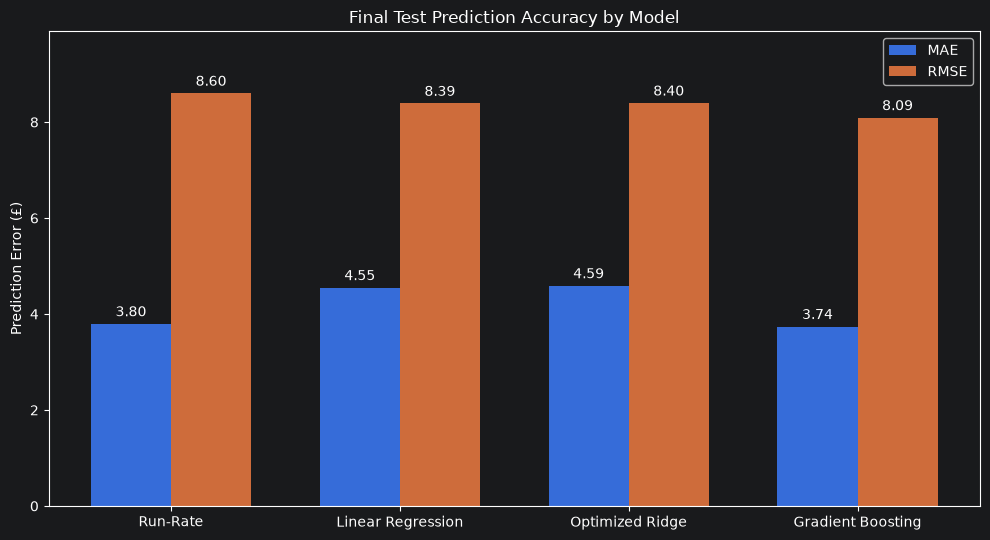

In [40]:
# Plot final test MAE and RMSE and save the figure to reports/Phase4
import matplotlib.pyplot as plt
from pathlib import Path

figures_dir = Path("../reports/Phase4")
figures_dir.mkdir(parents=True, exist_ok=True)

model_labels = [
    "Run-Rate",
    "Linear Regression",
    "Optimized Ridge",
    "Gradient Boosting"
]

x = np.arange(len(final_summary_df))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5.5))

mae_bars = ax.bar(
    x - width / 2,
    final_summary_df["MAE_gbp"],
    width,
    label="MAE"
)

rmse_bars = ax.bar(
    x + width / 2,
    final_summary_df["RMSE_gbp"],
    width,
    label="RMSE"
)

ax.set_xticks(x)
ax.set_xticklabels(model_labels)
ax.set_ylabel("Prediction Error (£)")
ax.set_title("Final Test Prediction Accuracy by Model")
ax.legend()

ax.bar_label(mae_bars, fmt="%.2f", padding=3)
ax.bar_label(rmse_bars, fmt="%.2f", padding=3)

ax.set_ylim(0, final_summary_df["RMSE_gbp"].max() * 1.15)

plt.tight_layout()

plt.savefig(
    figures_dir / "final_model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Step 27B: Findings

The final model accuracy comparison shows that optimized Gradient Boosting achieved the lowest MAE (£3.75) and RMSE (£8.10), indicating the strongest overall point-prediction performance.

The run-rate baseline achieved the second-lowest MAE (£3.80), demonstrating that a simple consumption-based forecasting approach remained competitive.

Linear Regression and optimized Ridge produced similar results, with MAE values of approximately £4.55 and £4.59, respectively. Although both achieved slightly lower RMSE than the run-rate baseline, their average absolute prediction errors were higher.

Overall, the figure confirms that Gradient Boosting provided the best balance of average prediction accuracy and reduced large prediction errors during the final test period.

### Step 27C: Final Prediction Interval Coverage Comparison

A bar chart is generated to compare the empirical coverage of the nominal 90% conformal prediction intervals across the four forecasting approaches.

Empirical coverage represents the percentage of actual final electricity bills contained within their corresponding prediction intervals.

A horizontal reference line indicates the nominal 90% coverage target.

The visualization highlights differences in uncertainty estimation reliability and identifies the extent to which each forecasting approach falls below the intended coverage level.

The figure uses the consolidated final test results without recalibrating or modifying the prediction intervals.

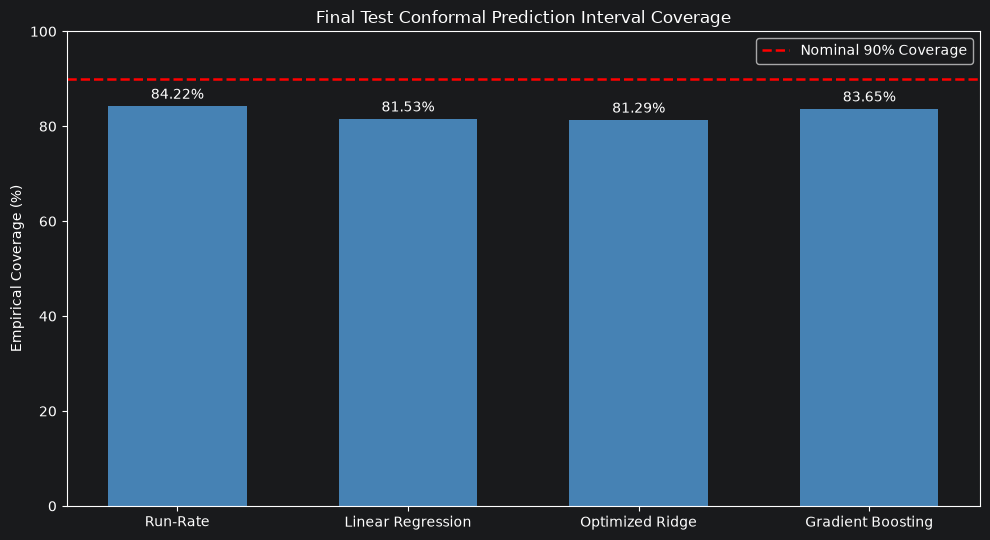

In [41]:
# Plot empirical prediction interval coverage against the 90% target
fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    model_labels,
    final_summary_df["Coverage_%"],
    color="steelblue",
    width=0.6
)

ax.axhline(
    y=90,
    color="red",
    linestyle="--",
    linewidth=1.8,
    label="Nominal 90% Coverage"
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.set_ylabel("Empirical Coverage (%)")
ax.set_title("Final Test Conformal Prediction Interval Coverage")
ax.set_ylim(0, 100)
ax.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "final_interval_coverage_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Step 27C: Findings

The final conformal prediction interval comparison shows that none of the four forecasting approaches achieved the nominal 90% empirical coverage on the reserved test period.

The run-rate baseline achieved the highest coverage (84.22%), followed by optimized Gradient Boosting (83.46%), Linear Regression (81.53%), and optimized Ridge (81.29%).

The observed coverage shortfalls ranged from approximately 5.78 to 8.71 percentage points below the nominal target.

These findings indicate that the conformal intervals did not adequately represent forecasting uncertainty during the final test period. Although the forecasting models demonstrated strong point-prediction performance, their uncertainty estimates were less reliable.

The results highlight the importance of evaluating prediction interval coverage separately from point-prediction accuracy.

### Step 27D: Prediction Accuracy Across Forecasting Days

A line chart is generated to compare Mean Absolute Error (MAE) across forecasting days 7, 14, and 21 for the four forecasting approaches.

The visualization examines how prediction accuracy changes as additional electricity consumption observations become available during the billing month.

MAE is measured in British pounds (£), with lower values indicating more accurate forecasts.

The figure uses the previously calculated day-specific final test results and does not involve model retraining or additional evaluation procedures.

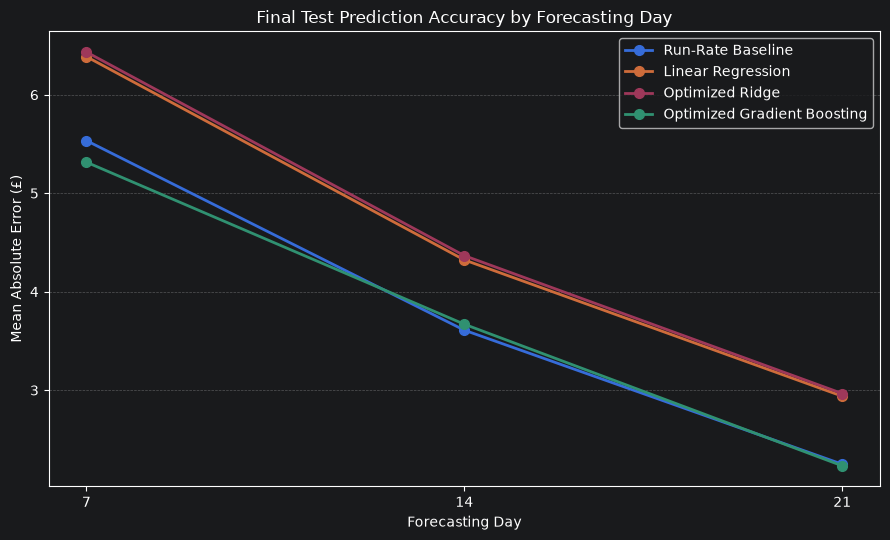

In [42]:
# Plot final test MAE across forecasting days and save the figure
fig, ax = plt.subplots(figsize=(9, 5.5))

for model_name, group in final_day_accuracy_df.groupby("Model", sort=False):

    group = group.sort_values("Day")

    ax.plot(
        group["Day"],
        group["MAE_gbp"],
        marker="o",
        linewidth=2,
        markersize=7,
        label=model_name
    )

ax.set_xticks([7, 14, 21])
ax.set_xlabel("Forecasting Day")
ax.set_ylabel("Mean Absolute Error (£)")
ax.set_title("Final Test Prediction Accuracy by Forecasting Day")

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "final_accuracy_by_forecasting_day.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Step 27D: Findings

The day-specific accuracy comparison demonstrates that forecasting performance improved consistently as additional electricity consumption information became available.

All four forecasting approaches recorded decreasing MAE from day 7 to day 21. Optimized Gradient Boosting achieved the lowest MAE on days 7 (£5.3294) and 21 (£2.2371), while the run-rate baseline achieved the lowest MAE on day 14 (£3.6089).

For Gradient Boosting, MAE decreased by approximately 58% between days 7 and 21, indicating a substantial improvement in forecasting accuracy as the billing month progressed.

Linear Regression and optimized Ridge exhibited similar performance patterns but consistently produced higher MAE values than the run-rate baseline and Gradient Boosting.

Overall, the findings demonstrate the value of incorporating additional consumption observations when forecasting household electricity bills.

### Step 27E: Prediction Interval Coverage Across Forecasting Days

A line chart is generated to compare empirical coverage of the nominal 90% conformal prediction intervals across forecasting days 7, 14, and 21.

Each forecasting approach is represented by a separate line, while a horizontal reference line indicates the nominal 90% coverage target.

The visualization examines whether prediction interval reliability improves or deteriorates as additional electricity consumption observations become available.

The analysis uses the previously calculated day-specific final test coverage results without modifying the prediction intervals.

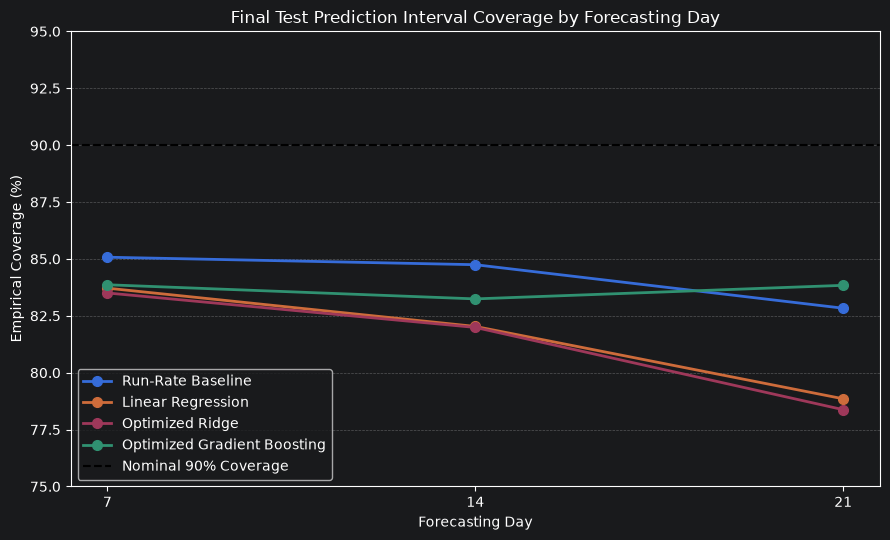

In [43]:
# Plot final test prediction interval coverage across forecasting days
fig, ax = plt.subplots(figsize=(9, 5.5))

for model_name, group in final_interval_df.groupby("Model", sort=False):

    group = group.sort_values("Day")

    ax.plot(
        group["Day"],
        group["Coverage_%"],
        marker="o",
        linewidth=2,
        markersize=7,
        label=model_name
    )

ax.axhline(
    y=90,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Nominal 90% Coverage"
)

ax.set_xticks([7, 14, 21])
ax.set_xlabel("Forecasting Day")
ax.set_ylabel("Empirical Coverage (%)")
ax.set_title("Final Test Prediction Interval Coverage by Forecasting Day")
ax.set_ylim(75, 95)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "final_coverage_by_forecasting_day.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Step 27E: Findings

The day-specific prediction interval comparison shows that none of the forecasting approaches achieved the nominal 90% empirical coverage on days 7, 14, or 21.

The run-rate baseline achieved the highest coverage on days 7 (85.07%) and 14 (84.75%), while optimized Gradient Boosting achieved the highest coverage on day 21 (83.36%).

Linear Regression and optimized Ridge exhibited declining coverage as the billing month progressed, reaching 78.85% and 78.38%, respectively, on day 21. In contrast, Gradient Boosting maintained relatively stable coverage across the three forecasting days, ranging from 83.26% to 83.76%.

Although point-prediction accuracy improved with additional consumption observations, prediction interval coverage did not show a corresponding improvement.

These findings demonstrate that improved forecasting accuracy does not necessarily translate into more reliable uncertainty estimates.

### Step 27F: Prediction Interval Width Across Forecasting Days

A line chart is generated to compare the average width of the conformal prediction intervals across forecasting days 7, 14, and 21 for the four forecasting approaches.

Average interval width is calculated as:

`Average Width (£) = (1/n) × Σ (Upper Bound − Lower Bound)`

Narrower prediction intervals indicate greater precision in the reported uncertainty range. However, narrower intervals are desirable only when they maintain adequate empirical coverage.

The visualization examines how prediction interval width changes as more electricity consumption information becomes available during the billing month.

The chart uses the previously calculated final test interval widths without modifying the models or their calibration adjustments.

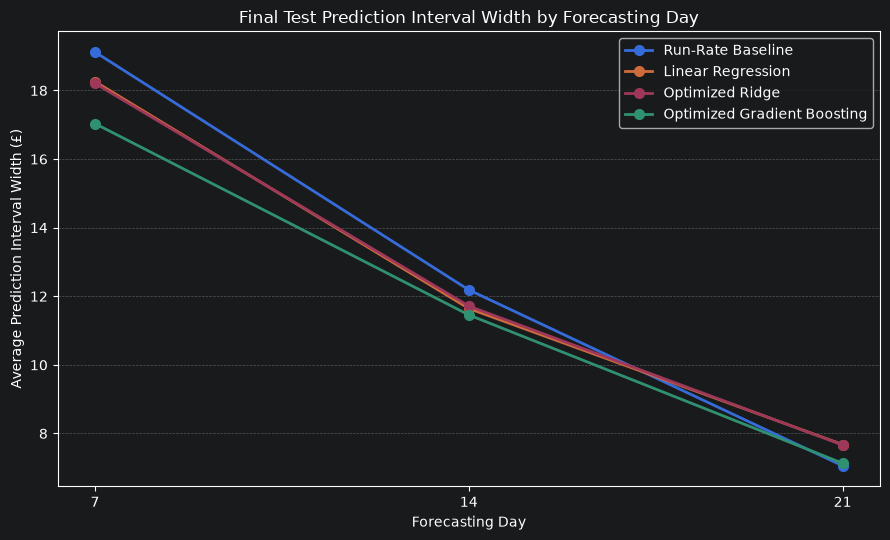

In [44]:
# Plot average prediction interval width across forecasting days
fig, ax = plt.subplots(figsize=(9, 5.5))

for model_name, group in final_interval_df.groupby("Model", sort=False):

    group = group.sort_values("Day")

    ax.plot(
        group["Day"],
        group["Average_Width_gbp"],
        marker="o",
        linewidth=2,
        markersize=7,
        label=model_name
    )

ax.set_xticks([7, 14, 21])
ax.set_xlabel("Forecasting Day")
ax.set_ylabel("Average Prediction Interval Width (£)")
ax.set_title("Final Test Prediction Interval Width by Forecasting Day")

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "final_interval_width_by_forecasting_day.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Step 27F: Findings

The prediction interval width comparison demonstrates that all four forecasting approaches produced progressively narrower intervals as the billing month advanced from day 7 to day 21.

Optimized Gradient Boosting generated the narrowest average prediction intervals across all three forecasting days, with widths of £16.98, £11.46, and £7.03, respectively. This represents an approximate 58.6% reduction between days 7 and 21.

The run-rate baseline produced wider intervals on days 7 and 14, while Linear Regression and optimized Ridge generated similar interval widths throughout the forecasting period.

The reduction in interval width is consistent with decreasing remaining consumption uncertainty as more of the billing month is observed. However, the intervals did not achieve the nominal 90% empirical coverage on the final test period.

These findings highlight the distinction between prediction interval precision and reliability: narrower intervals are not necessarily better when their empirical coverage falls below the intended target.

### Step 27G: Monthly Prediction Interval Coverage on Day 21

A line chart is generated to examine monthly empirical coverage of the nominal 90% conformal prediction intervals on forecasting day 21.

The visualization compares the four forecasting approaches across October 2013, November 2013, December 2013, and January 2014.

A horizontal reference line indicates the nominal 90% coverage target.

Day 21 is examined because the preceding diagnostic analysis identified particularly substantial coverage deterioration in December 2013 at this forecasting stage.

The chart provides a descriptive assessment of temporal variation in uncertainty estimation reliability. It uses existing final test results without retraining models or recalibrating prediction intervals.

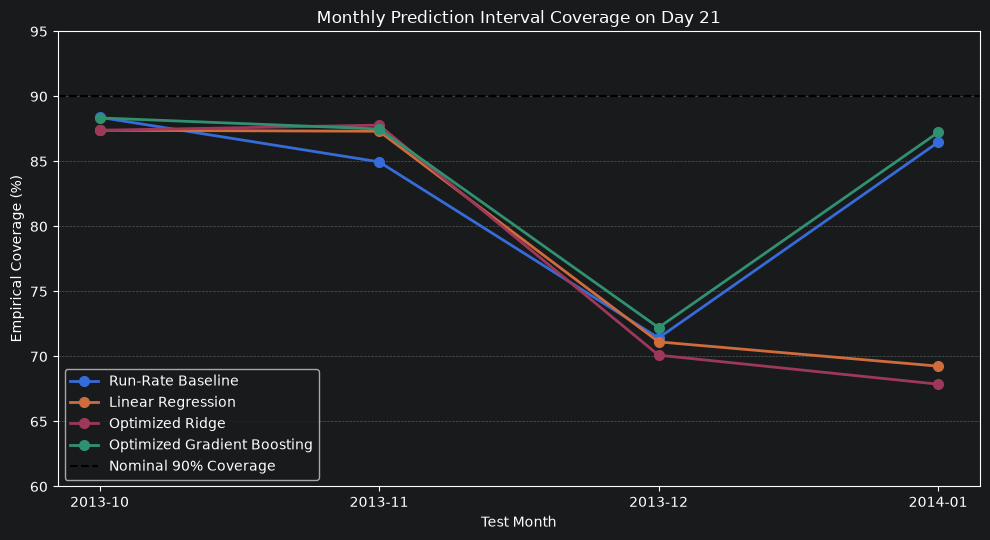

In [45]:
# Plot monthly prediction interval coverage on forecasting day 21
day21_coverage = monthly_interval_df.loc[
    monthly_interval_df["Day"] == 21
].copy()

fig, ax = plt.subplots(figsize=(10, 5.5))

for model_name, group in day21_coverage.groupby("Model", sort=False):

    group = group.sort_values("Month")

    ax.plot(
        group["Month"],
        group["Coverage_%"],
        marker="o",
        linewidth=2,
        markersize=7,
        label=model_name
    )

ax.axhline(
    y=90,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Nominal 90% Coverage"
)

ax.set_xlabel("Test Month")
ax.set_ylabel("Empirical Coverage (%)")
ax.set_title("Monthly Prediction Interval Coverage on Day 21")
ax.set_ylim(60, 95)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "monthly_interval_coverage_day21.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Step 27G: Findings

The monthly coverage comparison on forecasting day 21 revealed substantial temporal variation in prediction interval reliability.

All four forecasting approaches experienced a pronounced decline in empirical coverage during December 2013. Coverage fell to 71.42% for the run-rate baseline, 71.12% for Linear Regression, 70.10% for optimized Ridge, and 71.57% for optimized Gradient Boosting.

In January 2014, coverage recovered to 86.47% for the run-rate baseline and 87.00% for Gradient Boosting. However, Linear Regression and optimized Ridge continued to exhibit substantial undercoverage, achieving only 69.25% and 67.87%, respectively.

The shared deterioration in December suggests that changes in forecasting error characteristics affected all four approaches. These variations are consistent with differences between the calibration and test periods, although the specific causes cannot be established from the available results.

Overall, the findings demonstrate that fixed conformal prediction intervals did not maintain stable empirical coverage across the final test months.

### Step 27H: Monthly Prediction Bias on Forecasting Day 21

A line chart is generated to compare monthly Mean Error (ME) across the four forecasting approaches on day 21.

Mean Error is calculated as:

`ME = (1/n) × Σ(Predicted Billᵢ − Actual Billᵢ)`

Positive values indicate average overprediction, while negative values indicate average underprediction. A horizontal reference line at zero represents the absence of average directional bias.

The visualization examines whether systematic prediction bias varied between October 2013 and January 2014, particularly during December, when prediction interval coverage deteriorated substantially.

The figure uses previously calculated final test predictions and does not involve model retraining or recalibration.

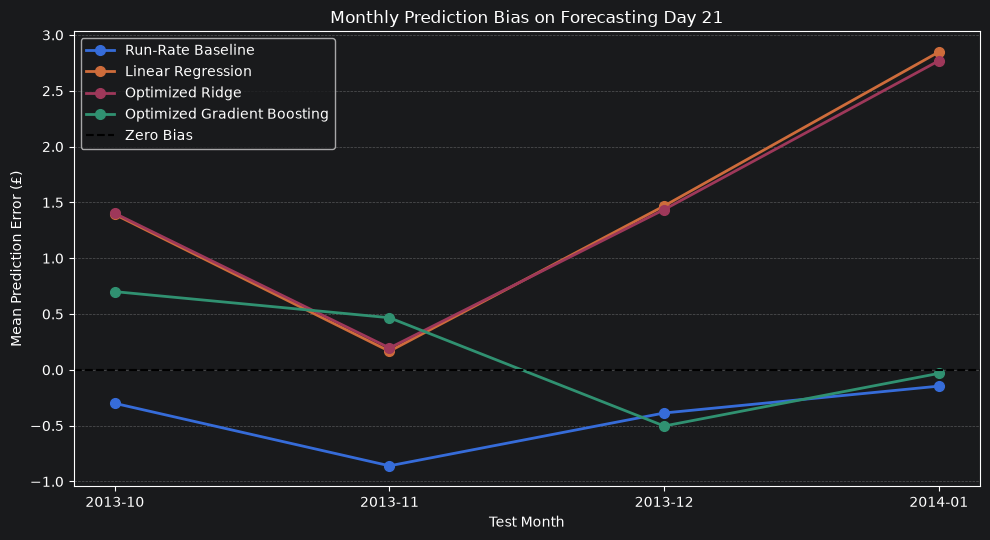

In [46]:
# Plot monthly prediction bias on forecasting day 21
day21_bias = monthly_bias_df.loc[
    monthly_bias_df["Day"] == 21
].copy()

fig, ax = plt.subplots(figsize=(10, 5.5))

for model_name, group in day21_bias.groupby("Model", sort=False):

    group = group.sort_values("Month")

    ax.plot(
        group["Month"],
        group["Mean_Error_gbp"],
        marker="o",
        linewidth=2,
        markersize=7,
        label=model_name
    )

ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Zero Bias"
)

ax.set_xlabel("Test Month")
ax.set_ylabel("Mean Prediction Error (£)")
ax.set_title("Monthly Prediction Bias on Forecasting Day 21")

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "monthly_prediction_bias_day21.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Step 27H: Findings

The monthly prediction bias comparison on forecasting day 21 revealed distinct patterns across the four forecasting approaches.

The run-rate baseline consistently underestimated final electricity bills, recording negative mean errors throughout the test period. However, the magnitude of its directional bias remained relatively small.

Linear Regression and optimized Ridge generally overestimated final bills, with their largest positive biases occurring in January 2014. Their mean errors reached £2.8473 and £2.7690, respectively.

Optimized Gradient Boosting exhibited comparatively small directional bias, with mean errors ranging from -£0.5631 in December to +£0.7115 in October. Its January mean error was approximately zero (£0.0281).

Despite relatively small mean errors for the run-rate baseline and Gradient Boosting in December, prediction interval coverage deteriorated substantially. This indicates that December's undercoverage was associated with larger individual prediction errors rather than systematic directional bias alone.

Overall, the findings demonstrate that forecasting error characteristics varied across models and months, reinforcing the importance of evaluating both prediction accuracy and uncertainty reliability.

### What Did Our Experiment Establish?

Our research question was:

*On day d of a billing month, how accurately can a household's month-end bill be projected, with a prediction interval, from its smart meter readings?*

Our experiments produced three principal findings:

1. **Accurate forecasting is achievable.** Optimized Gradient Boosting achieved an overall MAE of £3.75 and R² of 0.9601 on the reserved test period.

2. **Forecasting accuracy improves as the month progresses.** Gradient Boosting's MAE decreased from £5.33 on day 7 to £2.24 on day 21.

3. **Uncertainty estimation remains a limitation.** None of the models achieved the nominal 90% prediction interval coverage on the final test period. The highest observed coverage was 84.22%, achieved by the run-rate baseline.

These findings address both components of our research question: the accuracy of month-end electricity bill projections at different forecasting days and the reliability of their associated prediction intervals.